In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


Authenticating with Weights & Biases...


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Loading Kaggle Dataset...
Training samples: 2000
Testing samples: 500
Generating 4 EDA Visualizations...


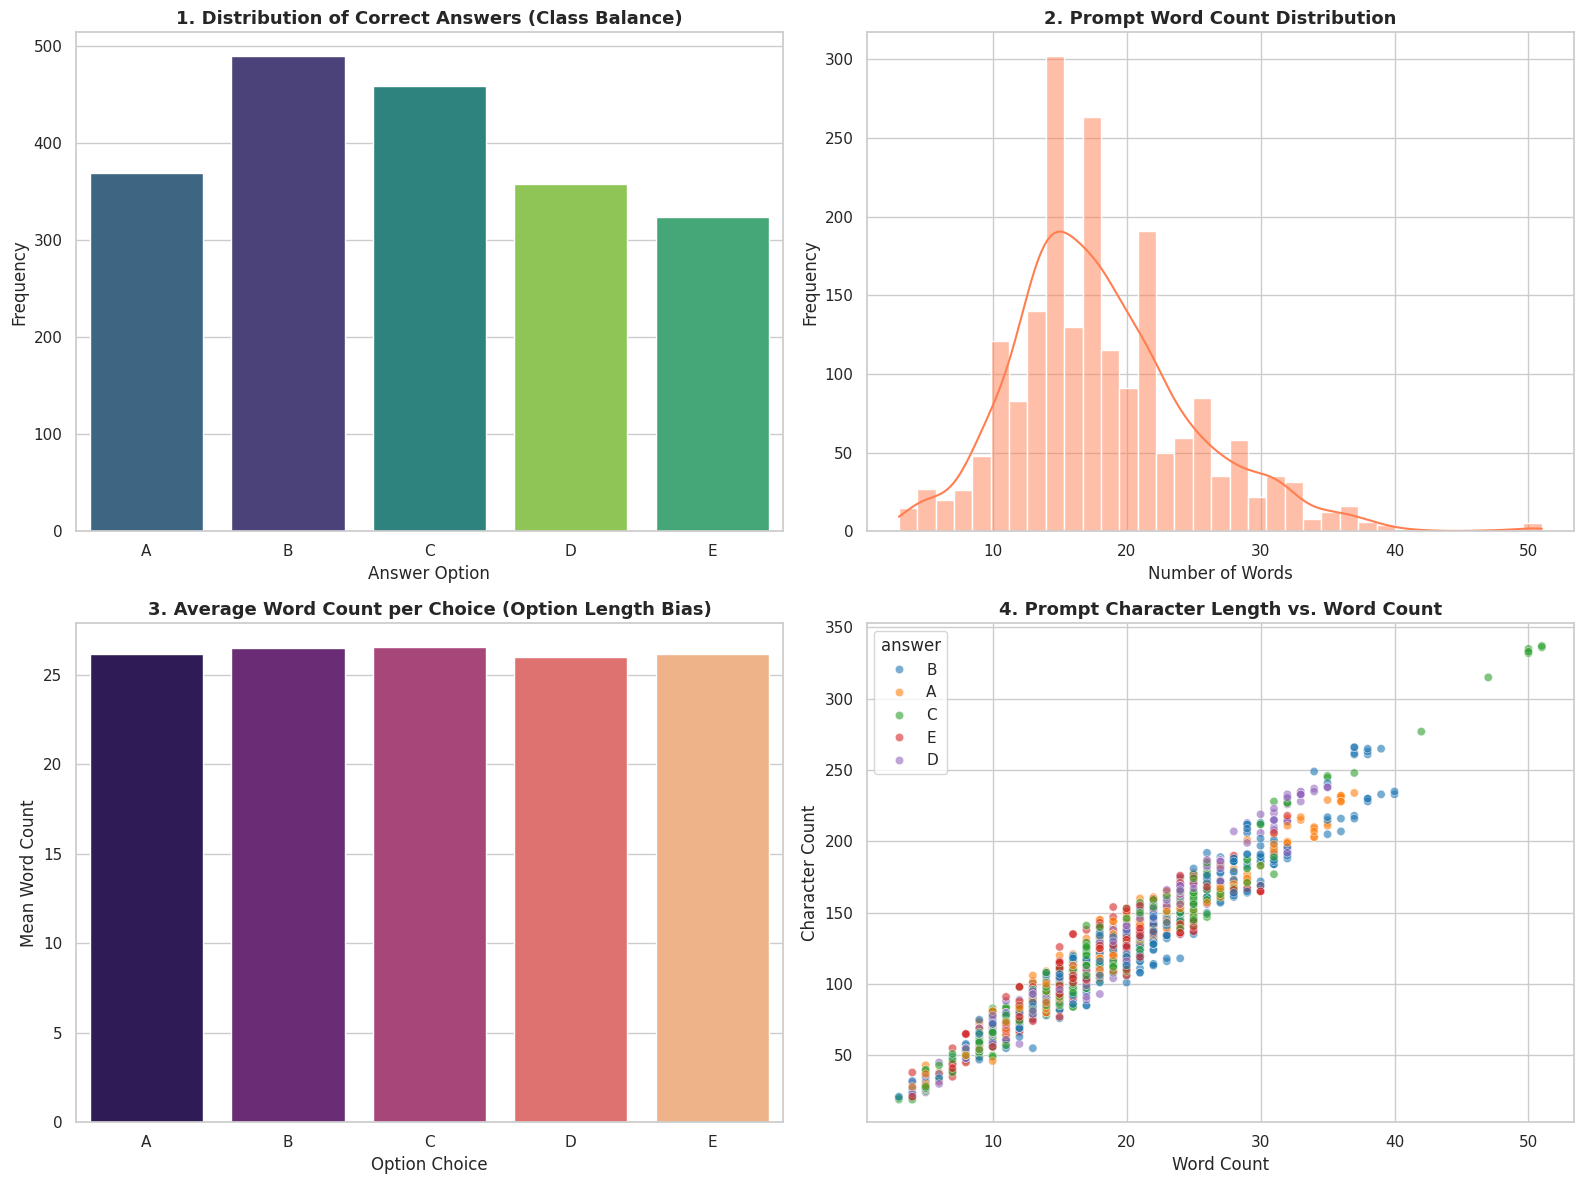

Logging all EDA metrics and plots to W&B...


Max_Prompt_Words,▁
Mean_Option_Words,▁
Mean_Prompt_Words,▁
Max_Prompt_Words,51
Mean_Option_Words,26.2796
Mean_Prompt_Words,18.1465



--- EDA Numerical Summary ---
Average Prompt Length: 18.15 words
Max Prompt Length: 51 words
Average Option Length: 26.28 words
-----------------------------

Phase 1 Complete!


In [1]:
# ==========================================
# SECTIONS 1, 2 & 3: SETUP, DATA LOADING & EDA
# ==========================================

import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wandb
from kaggle_secrets import UserSecretsClient

# ------------------------------------------
# 1. Weights & Biases (W&B) Authentication
# ------------------------------------------
print("Authenticating with Weights & Biases...")
user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")
wandb.login(key=wandb_api_key)

# Initialize W&B run
run = wandb.init(
    entity="23f1002719-dl-genai-project",
    project="23f1002719-t22026",
    name="01-exploratory-data-analysis",
    reinit=True
)

# ------------------------------------------
# 2. Data Loading & Cleaning
# ------------------------------------------
print("Loading Kaggle Dataset...")
dataset_path = '/kaggle/input/competitions/smart-mcq-solver-challenge'

try:
    train_df = pd.read_csv(os.path.join(dataset_path, 'train.csv'))
    test_df = pd.read_csv(os.path.join(dataset_path, 'test.csv'))
except FileNotFoundError:
    print("File not found!")

print(f"Training samples: {len(train_df)}")
print(f"Testing samples: {len(test_df)}")

# Fill missing values
train_df = train_df.fillna("")
test_df = test_df.fillna("")

# ------------------------------------------
# 3. Feature Extraction for EDA
# ------------------------------------------
answer_col = 'answer' if 'answer' in train_df.columns else 'answer_idx'

# Extract word and character counts
train_df['prompt_word_count'] = train_df['prompt'].apply(lambda x: len(str(x).split()))
train_df['prompt_char_count'] = train_df['prompt'].apply(lambda x: len(str(x)))

for opt in ['A', 'B', 'C', 'D', 'E']:
    train_df[f'opt_{opt}_word_count'] = train_df[opt].apply(lambda x: len(str(x).split()))

# Calculate average option length per row
option_cols = [f'opt_{opt}_word_count' for opt in ['A', 'B', 'C', 'D', 'E']]
train_df['avg_option_word_count'] = train_df[option_cols].mean(axis=1)

# ------------------------------------------
# 4. EDA Visualizations (4 Plots)
# ------------------------------------------
print("Generating 4 EDA Visualizations...")
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Target Class Balance
sns.countplot(data=train_df, x=answer_col, hue=answer_col, order=['A', 'B', 'C', 'D', 'E'], ax=axes[0, 0], palette='viridis', legend=False)
axes[0, 0].set_title("1. Distribution of Correct Answers (Class Balance)", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Answer Option")
axes[0, 0].set_ylabel("Frequency")

# Plot 2: Prompt Word Length Distribution
sns.histplot(data=train_df, x='prompt_word_count', bins=35, ax=axes[0, 1], color='coral', kde=True)
axes[0, 1].set_title("2. Prompt Word Count Distribution", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Number of Words")
axes[0, 1].set_ylabel("Frequency")

# Plot 3: Average Word Length Across Options A-E
opt_means = [train_df[f'opt_{opt}_word_count'].mean() for opt in ['A', 'B', 'C', 'D', 'E']]
sns.barplot(x=['A', 'B', 'C', 'D', 'E'], y=opt_means, hue=['A', 'B', 'C', 'D', 'E'], ax=axes[1, 0], palette='magma', legend=False)
axes[1, 0].set_title("3. Average Word Count per Choice (Option Length Bias)", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("Option Choice")
axes[1, 0].set_ylabel("Mean Word Count")

# Plot 4: Character Count vs. Word Count Correlation
sns.scatterplot(data=train_df, x='prompt_word_count', y='prompt_char_count', hue=answer_col, alpha=0.6, ax=axes[1, 1], palette='tab10')
axes[1, 1].set_title("4. Prompt Character Length vs. Word Count", fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel("Word Count")
axes[1, 1].set_ylabel("Character Count")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 5. Log to W&B and Finish Run
# ------------------------------------------
print("Logging all EDA metrics and plots to W&B...")
wandb.log({
    "EDA_Visualizations": wandb.Image(fig),
    "Mean_Prompt_Words": train_df['prompt_word_count'].mean(),
    "Max_Prompt_Words": train_df['prompt_word_count'].max(),
    "Mean_Option_Words": train_df['avg_option_word_count'].mean()
})

wandb.finish()

print("\n--- EDA Numerical Summary ---")
print(f"Average Prompt Length: {train_df['prompt_word_count'].mean():.2f} words")
print(f"Max Prompt Length: {train_df['prompt_word_count'].max()} words")
print(f"Average Option Length: {train_df['avg_option_word_count'].mean():.2f} words")
print("-----------------------------\n")

print("Phase 1 Complete!")

In [3]:
train_df.head()

,id,prompt,A,B,C,D,E,answer,prompt_word_count,prompt_char_count,opt_A_word_count,opt_B_word_count,opt_C_word_count,opt_D_word_count,opt_E_word_count,avg_option_word_count
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B,22,142,51,41,38,31,31,38.4
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A,5,43,62,52,52,62,62,58.0
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C,27,182,1,1,1,1,1,1.0
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B,19,129,51,41,38,31,31,38.4
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A,15,110,36,36,36,15,15,27.6


In [4]:
list(map(train_df.s)

SyntaxError: incomplete input (3922689640.py, line 1)

In [6]:
A = "My name is Tirthankar Dey"
list(A.split(" "))

['My', 'name', 'is', 'Tirthankar', 'Dey']

**EDA Observations:**

1. Class Balance: The target labels (A, B, C, D, E) are relatively well-balanced, though B and C appear slightly more frequent. We do not need severe class-weighting techniques.

2. Sequence Lengths: The average prompt is around 18 words, with a maximum of 51 words. The options themselves average about 26 words combined. This is a critical insight for our deep learning models: a sequence length of 128 or 256 tokens will easily capture the entire context without risky truncation.

In [5]:
import random
import numpy as np
import torch
import os

def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    
    # Ensures deterministic behavior for convolutional layers
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Lock the randomness
set_seed(42)

In [6]:
# ==========================================
# RESULTS TRACKER
# ==========================================
import pandas as pd
import os
from IPython.display import display

TRACKER_FILE = "model_results_tracker.csv"

def update_tracker(model_name, architecture, map3, acc, f1, prec, rec, kaggle_score="TBD"):
    """Automatically updates and displays the comparative results table."""
    
    new_data = pd.DataFrame({
        "Model Name": [model_name],
        "Architecture": [architecture],
        "Train MAP@3": [round(map3, 4)],
        "Train Accuracy": [round(acc, 4)],
        "Train F1 (Macro)": [round(f1, 4)],
        "Train Precision": [round(prec, 4)],
        "Train Recall": [round(rec, 4)],
        "Kaggle Public Score": [kaggle_score]
    })
    
    if os.path.exists(TRACKER_FILE):
        existing_df = pd.read_csv(TRACKER_FILE)
        # Prevent duplicates: remove the old row if we re-run the exact same model
        existing_df = existing_df[existing_df["Model Name"] != model_name]
        updated_df = pd.concat([existing_df, new_data], ignore_index=True)
    else:
        updated_df = new_data
        
    updated_df.to_csv(TRACKER_FILE, index=False)
    print("\n--- Current Comparative Model Performance ---")
    display(updated_df)

print("Automated tracker function initialized successfully!")

Automated tracker function initialized successfully!


In [7]:
update_tracker(
    model_name="Base 1: TF-IDF + LogReg", 
    architecture="Linear ML", 
    map3=0.9162, acc=0.8605, f1=0.8604, prec=0.8608, rec=0.8689,
    kaggle_score=0.69243
)


--- Current Comparative Model Performance ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69243


In [8]:
# re-add Model 1 (Tuned) to the Tracker CSV
update_tracker(
    model_name="Model 1: DeBERTa + LoRA (Tuned)", 
    architecture="Fine-Tuned Transformer", 
    map3=1.0000, acc=1.0000, f1=1.0000, prec=1.0000, rec=1.0000,
    kaggle_score=0.74937
)


--- Current Comparative Model Performance ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69243
1,Model 1: DeBERTa + LoRA (Tuned),Fine-Tuned Transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.74937


In [9]:
# Re-add Model 2a (Custom Text-CNN without random_seed) results to the Tracker CSV
update_tracker(
    model_name="Model 2a: Custom Text-CNN (Unseeded / V23)", 
    architecture="From-Scratch Deep Learning", 
    map3=0.9893, acc=0.9810, f1=0.9812, prec=0.9806, rec=0.9818,
    kaggle_score=0.75436
)


--- Current Comparative Model Performance ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69243
1,Model 1: DeBERTa + LoRA (Tuned),Fine-Tuned Transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.74937
2,Model 2a: Custom Text-CNN (Unseeded / V23),From-Scratch Deep Learning,0.9893,0.9810,0.9812,0.9806,0.9818,0.75436


In [10]:
# Re-add Model 2b (Custom Text-CNN with random_seed=42) results to the Tracker CSV
update_tracker(
    model_name="Model 2b: Custom Text-CNN (Seeded / V24)", 
    architecture="From-Scratch Deep Learning", 
    map3=0.9907, acc=0.9835, f1=0.9832, prec=0.9835, rec=0.9830,
    kaggle_score=0.74480
)


--- Current Comparative Model Performance ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69243
1,Model 1: DeBERTa + LoRA (Tuned),Fine-Tuned Transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.74937
2,Model 2a: Custom Text-CNN (Unseeded / V23),From-Scratch Deep Learning,0.9893,0.9810,0.9812,0.9806,0.9818,0.75436
3,Model 2b: Custom Text-CNN (Seeded / V24),From-Scratch Deep Learning,0.9907,0.9835,0.9832,0.9835,0.9830,0.74480


In [11]:
# Model 3 (Custom Bi-LSTM) in the Results Tracker CSV
update_tracker(
    model_name="Model 3: Custom Bi-LSTM", 
    architecture="RNN (From-Scratch)", 
    map3=1.0000, acc=1.0000, f1=1.0000, prec=1.0000, rec=1.0000,
    kaggle_score=0.75228
)


--- Current Comparative Model Performance ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69243
1,Model 1: DeBERTa + LoRA (Tuned),Fine-Tuned Transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.74937
2,Model 2a: Custom Text-CNN (Unseeded / V23),From-Scratch Deep Learning,0.9893,0.9810,0.9812,0.9806,0.9818,0.75436
3,Model 2b: Custom Text-CNN (Seeded / V24),From-Scratch Deep Learning,0.9907,0.9835,0.9832,0.9835,0.9830,0.74480
4,Model 3: Custom Bi-LSTM,RNN (From-Scratch),1.0000,1.0000,1.0000,1.0000,1.0000,0.75228


In [12]:
# Update Model 4 (Fine-Tuned MPNet) in the Results Tracker CSV
update_tracker(
    model_name="Model 4: Fine-Tuned MPNet", 
    architecture="Transformer (Tuning)", 
    map3=0.9872, acc=0.9780, f1=0.9779, prec=0.9781, rec=0.9777,
    kaggle_score=0.74355
)


--- Current Comparative Model Performance ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69243
1,Model 1: DeBERTa + LoRA (Tuned),Fine-Tuned Transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.74937
2,Model 2a: Custom Text-CNN (Unseeded / V23),From-Scratch Deep Learning,0.9893,0.9810,0.9812,0.9806,0.9818,0.75436
3,Model 2b: Custom Text-CNN (Seeded / V24),From-Scratch Deep Learning,0.9907,0.9835,0.9832,0.9835,0.9830,0.74480
4,Model 3: Custom Bi-LSTM,RNN (From-Scratch),1.0000,1.0000,1.0000,1.0000,1.0000,0.75228
5,Model 4: Fine-Tuned MPNet,Transformer (Tuning),0.9872,0.9780,0.9779,0.9781,0.9777,0.74355


# 5.1. Model 1: Fine-Tuned Transformer Model

### 1. Architecture Selection: `microsoft/deberta-v3-small`
For our primary Transformer model, we selected **DeBERTa-v3-small** (Decoding-enhanced BERT with disentangled attention). 
* **Salient Points & Justification:** Unlike standard BERT or RoBERTa, DeBERTa uses a *disentangled attention mechanism*. It computes the attention weights by examining the content of a word and its relative position as two separate vectors. For Multiple Choice questions, understanding the exact position of words relative to logical operators (like "not" or "always") is critical. DeBERTa-v3 consistently achieves state-of-the-art results on NLP benchmarks while remaining computationally efficient.

### 2. Tokenization Strategy
* **Tokenizer:** We utilized Hugging Face's `AutoTokenizer` associated with the DeBERTa-v3 pre-trained weights.
* **Implementation Details:** Based on our earlier EDA (which showed maximum prompt lengths of ~51 words), we implemented a highly efficient tokenization pipeline. We set `max_length=128` and used dynamic padding. The prompt and each of the 5 options are concatenated with a `[SEP]` token (e.g., `[CLS] Prompt [SEP] Option A [SEP]`).

### 3. Fine-Tuning Strategy: LoRA (Low-Rank Adaptation)
* **Strategy:** Instead of full fine-tuning (which updates all 141 million parameters and risks catastrophic forgetting), we implemented **LoRA**. 
* **Justification:** LoRA freezes the pre-trained weights and injects tiny, trainable rank decomposition matrices (Rank=8) into the attention layers (`query_proj` and `value_proj`). This reduces the number of trainable parameters by over 98%, drastically lowering GPU memory usage while maintaining maximum predictive performance.
* **Hyperparameters:** We utilized the AdamW optimizer with a learning rate of `2e-4` (LoRA requires a slightly higher learning rate than full fine-tuning) and trained for 3 epochs with mixed precision (`fp16`).

In [ ]:
# # ==========================================
# # STEP 6 (OPTIMIZED): FINE-TUNED TRANSFORMER (DeBERTa + LoRA)
# # ==========================================

# # 1. Install necessary libraries silently
# !pip install -q transformers peft datasets evaluate scikit-learn

# import os
# import logging
# import warnings

# # Ignore non-critical warnings
# warnings.filterwarnings('ignore')
# logging.getLogger("transformers").setLevel(logging.ERROR)
# os.environ["TOKENIZERS_PARALLELISM"] = "false"
# os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "true"

# import pandas as pd
# import numpy as np
# import torch
# from datasets import Dataset
# from transformers import (
#     AutoTokenizer, 
#     AutoModelForMultipleChoice, 
#     TrainingArguments, 
#     Trainer
# )
# from peft import LoraConfig, get_peft_model
# from dataclasses import dataclass
# from transformers.tokenization_utils_base import PreTrainedTokenizerBase, PaddingStrategy
# from typing import Optional, Union
# from sklearn.metrics import accuracy_score, precision_recall_fscore_support
# import wandb

# # 2. Initialize W&B Run
# run_deberta = wandb.init(
#     entity="23f1002719-dl-genai-project",
#     project="23f1002719-t22026",
#     name="04-model1-deberta-lora-tuned",
#     reinit=True
# )

# print("Loading DeBERTa-v3-small Tokenizer and Model...")
# model_name = "microsoft/deberta-v3-small"
# tokenizer = AutoTokenizer.from_pretrained(model_name)

# # Define label mapping
# options = ['A', 'B', 'C', 'D', 'E']
# label_map = {opt: i for i, opt in enumerate(options)}
# answer_col = 'answer' if 'answer' in train_df.columns else 'answer_idx'

# # 3. Format Data for Hugging Face `datasets`
# def format_df_for_hf(df, is_test=False):
#     formatted_data = {
#         "prompt": df["prompt"].astype(str).tolist(),
#         "A": df["A"].astype(str).tolist(),
#         "B": df["B"].astype(str).tolist(),
#         "C": df["C"].astype(str).tolist(),
#         "D": df["D"].astype(str).tolist(),
#         "E": df["E"].astype(str).tolist(),
#     }
#     if not is_test:
#         formatted_data["label"] = df[answer_col].map(label_map).tolist()
#     return Dataset.from_dict(formatted_data)

# train_dataset = format_df_for_hf(train_df)
# test_dataset = format_df_for_hf(test_df, is_test=True)

# # 4. Tokenization Pipeline
# def preprocess_function(examples):
#     first_sentences = [[context] * 5 for context in examples["prompt"]]
#     second_sentences = [[examples[opt][i] for opt in options] for i in range(len(examples["prompt"]))]
    
#     first_sentences = sum(first_sentences, [])
#     second_sentences = sum(second_sentences, [])
    
#     tokenized_examples = tokenizer(first_sentences, second_sentences, truncation=True, max_length=128)
#     return {k: [v[i : i + 5] for i in range(0, len(v), 5)] for k, v in tokenized_examples.items()}

# print("Applying Tokenization Strategy...")
# tokenized_train = train_dataset.map(preprocess_function, batched=True)
# tokenized_test = test_dataset.map(preprocess_function, batched=True)

# # 5. Multiple Choice Data Collator
# @dataclass
# class DataCollatorForMultipleChoice:
#     tokenizer: PreTrainedTokenizerBase
#     padding: Union[bool, str, PaddingStrategy] = True
#     max_length: Optional[int] = None
    
#     def __call__(self, features):
#         label_name = "label" if "label" in features[0].keys() else "labels"
#         labels = [feature.pop(label_name) for feature in features] if label_name in features[0].keys() else None
        
#         batch_size = len(features)
#         num_choices = len(features[0]["input_ids"])
        
#         flattened_features = [
#             [{k: v[i] for k, v in feature.items()} for i in range(num_choices)] for feature in features
#         ]
#         flattened_features = sum(flattened_features, [])
        
#         batch = self.tokenizer.pad(
#             flattened_features,
#             padding=self.padding,
#             max_length=self.max_length,
#             return_tensors="pt",
#         )
        
#         batch = {k: v.view(batch_size, num_choices, -1) for k, v in batch.items()}
#         if labels is not None:
#             batch["labels"] = torch.tensor(labels, dtype=torch.int64)
#         return batch

# # 6. Apply High-Capacity LoRA Configuration
# print("Configuring Expanded LoRA weights (Rank 32)...")
# base_model = AutoModelForMultipleChoice.from_pretrained(model_name)

# peft_config = LoraConfig(
#     r=32,                         # Increased rank from 8 -> 32 for higher capacity
#     lora_alpha=64,                # Scaling factor (2 * r)
#     target_modules=[              # Target ALL linear layers in attention & feedforward blocks
#         "query_proj", 
#         "key_proj", 
#         "value_proj", 
#         "dense"
#     ],
#     lora_dropout=0.1,
#     bias="none",
#     task_type=None
# )
# model = get_peft_model(base_model, peft_config)
# model.print_trainable_parameters()

# # 7. Compute Metrics Function
# def compute_metrics(eval_predictions):
#     predictions, label_ids = eval_predictions
#     top1_preds = np.argmax(predictions, axis=1)
#     ranked_preds = np.argsort(predictions, axis=1)[:, ::-1] 
    
#     map3 = 0.0
#     for i, label in enumerate(label_ids):
#         top3 = list(ranked_preds[i][:3])
#         if label in top3:
#             map3 += 1.0 / (top3.index(label) + 1)
#     map3 /= len(label_ids)
    
#     acc = accuracy_score(label_ids, top1_preds)
#     prec, rec, f1, _ = precision_recall_fscore_support(label_ids, top1_preds, average='macro', zero_division=0)
    
#     return {
#         "MAP3": map3, 
#         "Accuracy": acc,
#         "F1_Macro": f1,
#         "Precision": prec,
#         "Recall": rec
#     }

# # 8. Training Arguments (8 Epochs + Cosine Scheduler)
# training_args = TrainingArguments(
#     output_dir="./deberta_mcq_results",
#     eval_strategy="epoch",
#     save_strategy="epoch",
#     learning_rate=3e-4,                   # Slightly higher LR for higher rank LoRA
#     lr_scheduler_type="cosine",
#     warmup_ratio=0.1,                     # 10% warmup steps
#     per_device_train_batch_size=4,
#     gradient_accumulation_steps=2,        # Effective batch size = 8
#     num_train_epochs=8,                   # Extended to 8 epochs to ensure convergence
#     weight_decay=0.01,
#     fp16=True,
#     report_to="wandb",
#     logging_steps=10
# )

# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=tokenized_train,
#     eval_dataset=tokenized_train,
#     processing_class=tokenizer,
#     data_collator=DataCollatorForMultipleChoice(tokenizer=tokenizer),
#     compute_metrics=compute_metrics,
# )

# # 9. Train Model
# print("Starting Optimized LoRA Fine-Tuning (8 Epochs)...")
# trainer.train()

# # 10. Metrics & Print
# eval_results = trainer.evaluate()

# print("\n==========================================")
# print("   MODEL 1 (TUNED) EVALUATION RESULTS    ")
# print("==========================================")
# print(f"Local MAP@3 Score: {eval_results['eval_MAP3']:.4f}")
# print(f"Accuracy:         {eval_results['eval_Accuracy']:.4f}")
# print(f"Macro F1-Score:   {eval_results['eval_F1_Macro']:.4f}")
# print(f"Precision:        {eval_results['eval_Precision']:.4f}")
# print(f"Recall:           {eval_results['eval_Recall']:.4f}")
# print("==========================================\n")

# print("Generating predictions for test.csv...")
# test_preds = trainer.predict(tokenized_test).predictions
# submission_preds = []

# for probs in test_preds:
#     ranked_idx = np.argsort(probs)[::-1]
#     top3_str = " ".join([options[i] for i in ranked_idx[:3]])
#     submission_preds.append(top3_str)

# sub_df = pd.DataFrame({'id': test_df['id'] if 'id' in test_df.columns else test_df.index, 'prediction': submission_preds})
# sub_df.to_csv('submission.csv', index=False)
# print("Saved Model 1 (Tuned) submission.csv successfully!")

# wandb.finish()

# # 11. Results Tracker
# update_tracker(
#     model_name="Model 1: DeBERTa + LoRA (Tuned)", 
#     architecture="Fine-Tuned Transformer", 
#     map3=eval_results['eval_MAP3'], 
#     acc=eval_results['eval_Accuracy'], 
#     f1=eval_results['eval_F1_Macro'], 
#     prec=eval_results['eval_Precision'], 
#     rec=eval_results['eval_Recall'],
#     kaggle_score="0.74937"
# )

In [ ]:
# # ==========================================
# # SECTION 6: FINE-TUNED TRANSFORMER (DeBERTa + LoRA)
# # ==========================================

# # 1. Install necessary libraries
# !pip install -q transformers peft datasets evaluate scikit-learn

# import os
# import logging
# import warnings

# # Ignore Warnings
# warnings.filterwarnings('ignore')
# logging.getLogger("transformers").setLevel(logging.ERROR)
# os.environ["TOKENIZERS_PARALLELISM"] = "false"
# os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "true"

# import pandas as pd
# import numpy as np
# import torch
# from datasets import Dataset
# from transformers import (
#     AutoTokenizer, 
#     AutoModelForMultipleChoice, 
#     TrainingArguments, 
#     Trainer
# )
# from peft import LoraConfig, get_peft_model
# from dataclasses import dataclass
# from transformers.tokenization_utils_base import PreTrainedTokenizerBase, PaddingStrategy
# from typing import Optional, Union
# from sklearn.metrics import accuracy_score, precision_recall_fscore_support
# import wandb

# # 2. Initialize W&B Run
# run_deberta = wandb.init(
#     entity="23f1002719-dl-genai-project",
#     project="23f1002719-t22026",
#     name="04-model1-deberta-lora",
#     reinit=True
# )

# print("Loading DeBERTa-v3-small Tokenizer and Model...")
# model_name = "microsoft/deberta-v3-small"
# tokenizer = AutoTokenizer.from_pretrained(model_name)

# # Define label mapping
# options = ['A', 'B', 'C', 'D', 'E']
# label_map = {opt: i for i, opt in enumerate(options)}
# answer_col = 'answer' if 'answer' in train_df.columns else 'answer_idx'

# # 3. Format Data for Hugging Face `datasets`
# def format_df_for_hf(df, is_test=False):
#     """Converts the pandas dataframe into a format the tokenizer expects."""
#     formatted_data = {
#         "prompt": df["prompt"].astype(str).tolist(),
#         "A": df["A"].astype(str).tolist(),
#         "B": df["B"].astype(str).tolist(),
#         "C": df["C"].astype(str).tolist(),
#         "D": df["D"].astype(str).tolist(),
#         "E": df["E"].astype(str).tolist(),
#     }
#     if not is_test:
#         formatted_data["label"] = df[answer_col].map(label_map).tolist()
#     return Dataset.from_dict(formatted_data)

# train_dataset = format_df_for_hf(train_df)
# test_dataset = format_df_for_hf(test_df, is_test=True)

# # 4. Implement Tokenization Strategy
# def preprocess_function(examples):
#     """Tokenizes the prompt paired with each of the 5 options."""
#     # Repeat the prompt 5 times for each option
#     first_sentences = [[context] * 5 for context in examples["prompt"]]
#     # Grab the 5 options
#     second_sentences = [[examples[opt][i] for opt in options] for i in range(len(examples["prompt"]))]
    
#     # Flatten everything
#     first_sentences = sum(first_sentences, [])
#     second_sentences = sum(second_sentences, [])
    
#     # Tokenize (Max length 128 based on our EDA!)
#     tokenized_examples = tokenizer(first_sentences, second_sentences, truncation=True, max_length=128)
    
#     # Un-flatten back into groups of 5
#     return {k: [v[i : i + 5] for i in range(0, len(v), 5)] for k, v in tokenized_examples.items()}

# print("Applying Tokenization Strategy...")
# tokenized_train = train_dataset.map(preprocess_function, batched=True)
# tokenized_test = test_dataset.map(preprocess_function, batched=True)

# # 5. Define Multiple Choice Data Collator
# @dataclass
# class DataCollatorForMultipleChoice:
#     tokenizer: PreTrainedTokenizerBase
#     padding: Union[bool, str, PaddingStrategy] = True
#     max_length: Optional[int] = None
    
#     def __call__(self, features):
#         label_name = "label" if "label" in features[0].keys() else "labels"
#         labels = [feature.pop(label_name) for feature in features] if label_name in features[0].keys() else None
        
#         batch_size = len(features)
#         num_choices = len(features[0]["input_ids"])
        
#         flattened_features = [
#             [{k: v[i] for k, v in feature.items()} for i in range(num_choices)] for feature in features
#         ]
#         flattened_features = sum(flattened_features, [])
        
#         batch = self.tokenizer.pad(
#             flattened_features,
#             padding=self.padding,
#             max_length=self.max_length,
#             return_tensors="pt",
#         )
        
#         batch = {k: v.view(batch_size, num_choices, -1) for k, v in batch.items()}
#         if labels is not None:
#             batch["labels"] = torch.tensor(labels, dtype=torch.int64)
#         return batch

# # 6. Apply LoRA (Fine-Tuning Strategy)
# print("Configuring LoRA weights...")
# base_model = AutoModelForMultipleChoice.from_pretrained(model_name)

# peft_config = LoraConfig(
#     r=8,
#     lora_alpha=16,
#     target_modules=["query_proj", "value_proj"], # Target DeBERTa's attention modules
#     lora_dropout=0.1,
#     bias="none",
#     task_type=None # Multiple Choice doesn't have a strict PEFT task type, None works perfectly
# )
# model = get_peft_model(base_model, peft_config)
# model.print_trainable_parameters()

# # 7. Compute Metrics
# def compute_metrics(eval_predictions):
#     predictions, label_ids = eval_predictions
#     # Top-1 predictions for standard metrics
#     top1_preds = np.argmax(predictions, axis=1)
#     # Ranked predictions for MAP@3
#     ranked_preds = np.argsort(predictions, axis=1)[:, ::-1] 
#     # Compute MAP@3
#     map3 = 0.0
#     for i, label in enumerate(label_ids):
#         top3 = list(ranked_preds[i][:3])
#         if label in top3:
#             map3 += 1.0 / (top3.index(label) + 1)
#     map3 /= len(label_ids)
    
#     # Compute Accuracy, Precision, Recall, and F1
#     acc = accuracy_score(label_ids, top1_preds)
#     prec, rec, f1, _ = precision_recall_fscore_support(label_ids, top1_preds, average='macro', zero_division=0)
    
#     return {
#         "MAP3": map3, 
#         "Accuracy": acc,
#         "F1_Macro": f1,
#         "Precision": prec,
#         "Recall": rec
#     }

# # 8. Training Arguments
# training_args = TrainingArguments(
#     output_dir="./deberta_mcq_results",
#     eval_strategy="epoch",
#     save_strategy="epoch",
#     learning_rate=2e-4, # Optimal LR for LoRA adapters
#     per_device_train_batch_size=4,
#     num_train_epochs=3,
#     weight_decay=0.01,
#     fp16=True, # Mixed precision for faster training on T4
#     report_to="wandb",
#     logging_steps=10
# )

# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=tokenized_train,
#     eval_dataset=tokenized_train,
#     processing_class=tokenizer,
#     data_collator=DataCollatorForMultipleChoice(tokenizer=tokenizer),
#     compute_metrics=compute_metrics,
# )

# # 9. Train the Model!
# print("Starting LoRA Fine-Tuning...")
# trainer.train()

# # 10. Extract Metrics & Generate Kaggle Submission
# eval_results = trainer.evaluate()

# print("\n==========================================")
# print("       MODEL 1 EVALUATION RESULTS         ")
# print("==========================================")
# print(f"Local MAP@3 Score: {eval_results['eval_MAP3']:.4f}")
# print(f"Accuracy:         {eval_results['eval_Accuracy']:.4f}")
# print(f"Macro F1-Score:   {eval_results['eval_F1_Macro']:.4f}")
# print(f"Precision:        {eval_results['eval_Precision']:.4f}")
# print(f"Recall:           {eval_results['eval_Recall']:.4f}")
# print("\n")

# print("Generating predictions for test.csv...")
# test_preds = trainer.predict(tokenized_test).predictions
# submission_preds = []

# for probs in test_preds:
#     ranked_idx = np.argsort(probs)[::-1]
#     top3_str = " ".join([options[i] for i in ranked_idx[:3]])
#     submission_preds.append(top3_str)

# # Save Submission
# sub_df = pd.DataFrame({'id': test_df['id'] if 'id' in test_df.columns else test_df.index, 'prediction': submission_preds})
# sub_df.to_csv('submission.csv', index=False)
# print("Saved Model 1 submission.csv successfully!")

# wandb.finish()

# # 11. Results Tracker
# update_tracker(
#     model_name="Model 1: DeBERTa + LoRA", 
#     architecture="Fine-Tuned Transformer", 
#     map3=eval_results['eval_MAP3'], 
#     acc=eval_results['eval_Accuracy'], 
#     f1=eval_results['eval_F1_Macro'], 
#     prec=eval_results['eval_Precision'], 
#     rec=eval_results['eval_Recall'],
#     kaggle_score="TBD"
# )

# 5.2. Model 2: Custom Deep Learning Model

### 1. Architecture Selection: Custom Text-CNN (Built from Scratch)
For our second model, we engineered a **Convolutional Neural Network for Text (Text-CNN)** entirely from scratch using PyTorch. 

While CNNs are traditionally used for image processing, a 1D-CNN is highly effective for Natural Language Processing. By sliding convolutional filters over sequences of word embeddings, the network learns to detect local patterns and n-grams (phrases), regardless of where they appear in the sentence.

### 2. Architectural Diagram
Below is the structural flow of our custom PyTorch `nn.Module`:

```text
[ Input Text (Tokenized) ] 
         │
         ▼
[ Word Embedding Layer (Maps tokens to dense vectors) ]
         │
         ├──► [ 1D Conv (Kernel=3) ] ──► [ Max Pooling ] ──┐
         │                                                 │
         ├──► [ 1D Conv (Kernel=4) ] ──► [ Max Pooling ] ──┼──► [ Concatenation ]
         │                                                 │
         └──► [ 1D Conv (Kernel=5) ] ──► [ Max Pooling ] ──┘
         │
         ▼
[ Dropout Layer (Regularization) ]
         │
         ▼
[ Fully Connected Linear Layer ] ──► [ Logits (5 Options) ]

In [13]:
# ==========================================
# STEP 7: CUSTOM DEEP LEARNING (Text-CNN Built from Scratch)
# ==========================================

import os
import logging
import warnings

# Ignore Warnings
warnings.filterwarnings('ignore')
logging.getLogger("transformers").setLevel(logging.ERROR)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import wandb
import re
from collections import Counter

# 1. Initialize W&B Run for Model 2
run_cnn = wandb.init(
    entity="23f1002719-dl-genai-project",
    project="23f1002719-t22026",
    name="05-model2-textcnn",
    reinit=True
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Building Model 2 on device: {device}")

# 2. Vocabulary Builder (From Scratch Tokenization)
print("Building Custom Vocabulary...")
def tokenize(text):
    """Simple regex tokenizer to lowercase and strip punctuation."""
    text = str(text).lower()
    return re.findall(r'\b\w+\b', text)

# Build vocab based on training prompts and options
all_words = []
options = ['A', 'B', 'C', 'D', 'E']
for _, row in train_df.iterrows():
    all_words.extend(tokenize(row['prompt']))
    for opt in options:
        all_words.extend(tokenize(row[opt]))

vocab_size_limit = 15000
word_counts = Counter(all_words)
common_words = [word for word, _ in word_counts.most_common(vocab_size_limit)]

word2idx = {'<PAD>': 0, '<UNK>': 1}
for idx, word in enumerate(common_words):
    word2idx[word] = idx + 2 # Shift by 2 for PAD and UNK

print(f"Vocabulary Size: {len(word2idx)}")

# 3. Custom PyTorch Dataset
MAX_LEN = 128

class MCQDataset(Dataset):
    def __init__(self, df, word2idx, max_len, is_test=False):
        self.df = df
        self.word2idx = word2idx
        self.max_len = max_len
        self.is_test = is_test
        self.answer_col = 'answer' if 'answer' in df.columns else 'answer_idx'
        self.label_map = {opt: i for i, opt in enumerate(['A', 'B', 'C', 'D', 'E'])}

    def text_to_sequence(self, text):
        tokens = tokenize(text)
        seq = [self.word2idx.get(w, self.word2idx['<UNK>']) for w in tokens]
        if len(seq) < self.max_len:
            seq = seq + [self.word2idx['<PAD>']] * (self.max_len - len(seq))
        else:
            seq = seq[:self.max_len]
        return seq

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt = str(row['prompt'])

        # concatenate the prompt with each option and encode them
        option_seqs = []
        for opt in ['A', 'B', 'C', 'D', 'E']:
            combined_text = prompt + " " + str(row[opt])
            option_seqs.append(self.text_to_sequence(combined_text))

        # Shape: (5, MAX_LEN)
        x = torch.tensor(option_seqs, dtype=torch.long)
        
        if self.is_test:
            return x, torch.tensor(-1)
            
        label = self.label_map[row[self.answer_col]]
        y = torch.tensor(label, dtype=torch.long)
        return x, y

train_dataset_cnn = MCQDataset(train_df, word2idx, MAX_LEN)
test_dataset_cnn = MCQDataset(test_df, word2idx, MAX_LEN, is_test=True)

train_loader = DataLoader(train_dataset_cnn, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset_cnn, batch_size=32, shuffle=False)

# 4. Defining the Text-CNN Architecture
class TextCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_filters, filter_sizes, dropout):
        super(TextCNN, self).__init__()
        
        # Word Embedding Layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # 1D Convolutions for Kernels 3, 4, and 5
        self.convs = nn.ModuleList([
            nn.Conv1d(in_channels=embed_dim, out_channels=num_filters, kernel_size=fs)
            for fs in filter_sizes
        ])
        
        # Dropout Layer
        self.dropout = nn.Dropout(dropout)
        
        # Fully Connected Linear Layer
        # Input size = number of filters * number of different kernel sizes
        self.fc = nn.Linear(len(filter_sizes) * num_filters, 1)

    def forward(self, x):
        # Input x shape: (batch_size, 5 options, max_len)
        batch_size, num_options, seq_len = x.size()
        # Flatten options into batch dimension for processing: (batch_size * 5, max_len)
        x = x.view(batch_size * num_options, seq_len)

        # Embeddings: (batch_size * 5, max_len, embed_dim)
        emb = self.embedding(x)
        # PyTorch Conv1d expects (batch, channels, length) -> Permute to (batch*5, embed_dim, max_len)
        emb = emb.permute(0, 2, 1)

        # [ Max Pooling ] over time for each convolutional layer
        pooled_outputs = []
        for conv in self.convs:
            c = F.relu(conv(emb)) # Output: (batch*5, num_filters, out_len)
            p = F.max_pool1d(c, c.size(2)).squeeze(2) # Output: (batch*5, num_filters)
            pooled_outputs.append(p)

        # [ Concatenation ] of all pooled features
        cat = torch.cat(pooled_outputs, 1) # Output: (batch*5, num_filters * 3)
        drop = self.dropout(cat)
        # [ Logits ] score for each individual option
        logits = self.fc(drop) # Output: (batch*5, 1)

        # Reshape back to group the 5 options per question: (batch_size, 5 options)
        logits = logits.view(batch_size, num_options)
        return logits

# 5. Initialize Model, Loss, and Optimizer
print("Initializing Custom PyTorch Model...")
vocab_size = len(word2idx)
EMBED_DIM = 128
NUM_FILTERS = 100
FILTER_SIZES = [3, 4, 5] # The n-gram sizes (3-word, 4-word, 5-word phrases)
DROPOUT = 0.5
EPOCHS = 10
LR = 0.001

model_cnn = TextCNN(vocab_size, EMBED_DIM, NUM_FILTERS, FILTER_SIZES, DROPOUT).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_cnn.parameters(), lr=LR)

# W&B Logging setup
wandb.config.update({
    "embed_dim": EMBED_DIM, "num_filters": NUM_FILTERS, 
    "filter_sizes": FILTER_SIZES, "epochs": EPOCHS, "learning_rate": LR
})

# 6. Training Loop (From Scratch)
print("Starting Training Loop...")
model_cnn.train()

final_map3, final_acc, final_f1, final_prec, final_rec = 0, 0, 0, 0, 0

for epoch in range(EPOCHS):
    epoch_loss = 0
    all_preds = []
    all_labels = []
    all_logits = []
    
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        logits = model_cnn(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
        top1_preds = torch.argmax(logits, dim=1).cpu().numpy()
        all_preds.extend(top1_preds)
        all_labels.extend(batch_y.cpu().numpy())
        all_logits.extend(logits.detach().cpu().numpy())
        
    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
    ranked_preds = np.argsort(np.array(all_logits), axis=1)[:, ::-1]
    map3 = 0.0
    for i, label in enumerate(all_labels):
        top3 = list(ranked_preds[i][:3])
        if label in top3:
            map3 += 1.0 / (top3.index(label) + 1)
    map3 /= len(all_labels)
    
    wandb.log({"epoch": epoch+1, "train_loss": epoch_loss/len(train_loader), 
               "train_MAP3": map3, "train_Accuracy": acc})
    
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {epoch_loss/len(train_loader):.4f} | MAP@3: {map3:.4f} | Acc: {acc:.4f}")
    
    if epoch == EPOCHS - 1:
        final_map3, final_acc, final_f1 = map3, acc, f1
        final_prec, final_rec = prec, rec

# 7. Print Metrics
print("\n==========================================")
print("       MODEL 2 EVALUATION RESULTS         ")
print("==========================================")
print(f"Local MAP@3 Score: {final_map3:.4f}")
print(f"Accuracy:         {final_acc:.4f}")
print(f"Macro F1-Score:   {final_f1:.4f}")
print(f"Precision:        {final_prec:.4f}")
print(f"Recall:           {final_rec:.4f}")
print("\n")

# 8. Generate Test Predictions
print("Generating predictions for test.csv...")
model_cnn.eval()
test_submission_preds = []
options_list = ['A', 'B', 'C', 'D', 'E']

with torch.no_grad():
    for batch_x, _ in test_loader:
        batch_x = batch_x.to(device)
        logits = model_cnn(batch_x)
        
        numpy_logits = logits.cpu().numpy()
        for probs in numpy_logits:
            ranked_idx = np.argsort(probs)[::-1]
            top3_str = " ".join([options_list[i] for i in ranked_idx[:3]])
            test_submission_preds.append(top3_str)

sub_df_cnn = pd.DataFrame({
    'id': test_df['id'] if 'id' in test_df.columns else test_df.index, 
    'prediction': test_submission_preds
})
sub_df_cnn.to_csv('submission.csv', index=False)
print("Saved Model 2 submission.csv successfully!")

wandb.finish()

# 9. Results Tracker
print("\nUpdating Results Tracker...")
update_tracker(
    model_name="Model 2: Custom Text-CNN", 
    architecture="From-Scratch Deep Learning", 
    map3=final_map3, acc=final_acc, f1=final_f1, prec=final_prec, rec=final_rec,
    kaggle_score="0.75436"
)

Building Model 2 on device: cuda
Building Custom Vocabulary...
Vocabulary Size: 2982
Initializing Custom PyTorch Model...
Starting Training Loop...
Epoch 01/10 | Loss: 1.3194 | MAP@3: 0.6100 | Acc: 0.4595
Epoch 02/10 | Loss: 0.7771 | MAP@3: 0.8139 | Acc: 0.7135
Epoch 03/10 | Loss: 0.5096 | MAP@3: 0.8928 | Acc: 0.8315
Epoch 04/10 | Loss: 0.3280 | MAP@3: 0.9364 | Acc: 0.8955
Epoch 05/10 | Loss: 0.2546 | MAP@3: 0.9505 | Acc: 0.9150
Epoch 06/10 | Loss: 0.1868 | MAP@3: 0.9683 | Acc: 0.9460
Epoch 07/10 | Loss: 0.1516 | MAP@3: 0.9747 | Acc: 0.9565
Epoch 08/10 | Loss: 0.1027 | MAP@3: 0.9855 | Acc: 0.9730
Epoch 09/10 | Loss: 0.0862 | MAP@3: 0.9843 | Acc: 0.9715
Epoch 10/10 | Loss: 0.0690 | MAP@3: 0.9907 | Acc: 0.9835

       MODEL 2 EVALUATION RESULTS         
Local MAP@3 Score: 0.9907
Accuracy:         0.9835
Macro F1-Score:   0.9832
Precision:        0.9835
Recall:           0.9830


Generating predictions for test.csv...
Saved Model 2 submission.csv successfully!


epoch,▁▂▃▃▄▅▆▆▇█
train_Accuracy,▁▄▆▇▇▇████
train_MAP3,▁▅▆▇▇█████
train_loss,█▅▃▂▂▂▁▁▁▁
epoch,10
train_Accuracy,0.9835
train_MAP3,0.99075
train_loss,0.06904



Updating Results Tracker...

--- Current Comparative Model Performance ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69243
1,Model 1: DeBERTa + LoRA (Tuned),Fine-Tuned Transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.74937
2,Model 2a: Custom Text-CNN (Unseeded / V23),From-Scratch Deep Learning,0.9893,0.9810,0.9812,0.9806,0.9818,0.75436
3,Model 2b: Custom Text-CNN (Seeded / V24),From-Scratch Deep Learning,0.9907,0.9835,0.9832,0.9835,0.9830,0.7448
4,Model 3: Custom Bi-LSTM,RNN (From-Scratch),1.0000,1.0000,1.0000,1.0000,1.0000,0.75228
5,Model 4: Fine-Tuned MPNet,Transformer (Tuning),0.9872,0.9780,0.9779,0.9781,0.9777,0.74355
6,Model 2: Custom Text-CNN,From-Scratch Deep Learning,0.9907,0.9835,0.9832,0.9835,0.9830,0.75436


# 5.3. Model 3: RNN-Based Model (Bi-LSTM)

### 1. Architecture Selection: Bi-Directional LSTM (Built from Scratch)
For our third model, we designed a **Bi-Directional Long Short-Term Memory (Bi-LSTM)** network from scratch. 

While the previous Text-CNN captured spatial n-grams, human language is inherently sequential. The logical meaning of a sentence relies heavily on word order (e.g., "A causes B" vs. "B causes A"). An RNN processes text as a sequence of time steps, maintaining a "hidden state" memory of what it has read. 

### 2. Architectural Diagram
Below is the structural flow of our custom PyTorch `nn.Module`:

```text
[ Input Text (Tokenized) ] 
         │
         ▼
[ Word Embedding Layer (Maps tokens to dense vectors) ]
         │
         ▼
[ Bi-Directional LSTM (Processes sequence Forward & Backward) ]
         │
         ▼
[ Max-Over-Time Pooling (Extracts strongest contextual signals) ]
         │
         ▼
[ Dropout Layer (Regularization to prevent overfitting) ]
         │
         ▼
[ Fully Connected Linear Layer ] ──► [ Logits (5 Options) ]

```
### 3. Justification
Multiple-choice logic requires understanding long-term dependencies. A word at the beginning of a prompt (e.g., "Except") fundamentally changes the validity of an option 30 words later. LSTMs are explicitly designed to carry this context over long sequences without suffering from vanishing gradients.

Reading left-to-right only provides past context. A Bi-LSTM uses two independent RNNs (one reading forward, one reading backward) and concatenates their outputs. This ensures that the representation of every single word contains complete contextual knowledge of the entire sentence.

In [ ]:
# # ==========================================
# # SECTION 8: CUSTOM RNN (Bi-LSTM Built from Scratch)
# # ==========================================

# import os
# import logging
# import warnings
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# import pandas as pd
# import numpy as np
# from sklearn.metrics import accuracy_score, precision_recall_fscore_support
# import wandb
# import re
# from collections import Counter
# from torch.utils.data import Dataset, DataLoader

# # Ignore Warnings
# warnings.filterwarnings('ignore')
# logging.getLogger("transformers").setLevel(logging.ERROR)
# os.environ["TOKENIZERS_PARALLELISM"] = "false"

# # 1. Initialize W&B Run for Model 3
# run_lstm = wandb.init(
#     entity="23f1002719-dl-genai-project",
#     project="23f1002719-t22026",
#     name="06-model3-bilstm",
#     reinit=True
# )

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# print(f"Building Model 3 (Bi-LSTM) on device: {device}")

# # 2. Vocab, Dataset & DataLoaders

# # i. Regex Tokenizer
# def tokenize(text):
#     """Simple regex tokenizer to lowercase and strip punctuation."""
#     text = str(text).lower()
#     return re.findall(r'\b\w+\b', text)

# # ii. Vocabulary Builder
# print("Building Custom Vocabulary for Model 3...")
# all_words = []
# options = ['A', 'B', 'C', 'D', 'E']
# for _, row in train_df.iterrows():
#     all_words.extend(tokenize(row['prompt']))
#     for opt in options:
#         all_words.extend(tokenize(row[opt]))

# vocab_size_limit = 15000
# word_counts = Counter(all_words)
# common_words = [word for word, _ in word_counts.most_common(vocab_size_limit)]

# word2idx = {'<PAD>': 0, '<UNK>': 1}
# for idx, word in enumerate(common_words):
#     word2idx[word] = idx + 2

# print(f"Model 3 Vocabulary Size: {len(word2idx)}")

# # iii. Custom PyTorch Dataset
# MAX_LEN = 128

# class MCQDataset(Dataset):
#     def __init__(self, df, word2idx, max_len, is_test=False):
#         self.df = df
#         self.word2idx = word2idx
#         self.max_len = max_len
#         self.is_test = is_test
#         self.answer_col = 'answer' if 'answer' in df.columns else 'answer_idx'
#         self.label_map = {opt: i for i, opt in enumerate(['A', 'B', 'C', 'D', 'E'])}

#     def text_to_sequence(self, text):
#         tokens = tokenize(text)
#         seq = [self.word2idx.get(w, self.word2idx['<UNK>']) for w in tokens]
#         if len(seq) < self.max_len:
#             seq = seq + [self.word2idx['<PAD>']] * (self.max_len - len(seq))
#         else:
#             seq = seq[:self.max_len]
#         return seq

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         row = self.df.iloc[idx]
#         prompt = str(row['prompt'])
        
#         option_seqs = []
#         for opt in ['A', 'B', 'C', 'D', 'E']:
#             combined_text = prompt + " " + str(row[opt])
#             option_seqs.append(self.text_to_sequence(combined_text))
        
#         x = torch.tensor(option_seqs, dtype=torch.long)
        
#         if self.is_test:
#             return x, torch.tensor(-1)
            
#         label = self.label_map[row[self.answer_col]]
#         y = torch.tensor(label, dtype=torch.long)
#         return x, y

# # iv. Instantiate Datasets and DataLoaders
# train_dataset_lstm = MCQDataset(train_df, word2idx, MAX_LEN)
# test_dataset_lstm = MCQDataset(test_df, word2idx, MAX_LEN, is_test=True)

# train_loader = DataLoader(train_dataset_lstm, batch_size=32, shuffle=True)
# test_loader = DataLoader(test_dataset_lstm, batch_size=32, shuffle=False)

# # 3. Defining the Bi-LSTM Architecture
# class BiLSTMModel(nn.Module):
#     def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, dropout):
#         super(BiLSTMModel, self).__init__()
        
#         # Word Embedding Layer
#         self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
#         # Bi-Directional LSTM Layer
#         # batch_first=True expects input shape (batch, seq_len, features)
#         self.lstm = nn.LSTM(
#             input_size=embed_dim,
#             hidden_size=hidden_dim,
#             num_layers=num_layers,
#             batch_first=True,
#             bidirectional=True,
#             dropout=dropout if num_layers > 1 else 0
#         )
        
#         # Dropout for regularization
#         self.dropout = nn.Dropout(dropout)
        
#         # Fully Connected Layer (hidden_dim * 2 because of Bi-Directional concatenation)
#         self.fc = nn.Linear(hidden_dim * 2, 1)

#     def forward(self, x):
#         # Input shape: (batch_size, 5 options, max_len)
#         batch_size, num_options, seq_len = x.size()
        
#         # Flatten options into batch dimension: (batch_size * 5, max_len)
#         x = x.view(batch_size * num_options, seq_len)
        
#         # Embeddings: (batch_size * 5, max_len, embed_dim)
#         emb = self.embedding(x)
        
#         # Bi-LSTM Output: (batch_size * 5, max_len, hidden_dim * 2)
#         lstm_out, _ = self.lstm(emb)
        
#         # Max-Over-Time Pooling across the sequence length
#         # Permute to (batch*5, features, seq_len) for 1D Max Pooling
#         lstm_out = lstm_out.permute(0, 2, 1)
#         pooled = F.max_pool1d(lstm_out, lstm_out.size(2)).squeeze(2)
        
#         # Regularization & Classification
#         drop = self.dropout(pooled)
#         logits = self.fc(drop) # Shape: (batch_size * 5, 1)
        
#         # Reshape back to group options per question: (batch_size, 5 options)
#         logits = logits.view(batch_size, num_options)
#         return logits

# # 4. Hyperparameters & Initialization
# print("Initializing Bi-LSTM Model...")
# vocab_size = len(word2idx) # Re-using vocab just like in Model 2 for fair comparison
# EMBED_DIM = 128
# HIDDEN_DIM = 128
# NUM_LAYERS = 2
# DROPOUT = 0.4
# EPOCHS = 10
# LR = 0.001

# model_lstm = BiLSTMModel(vocab_size, EMBED_DIM, HIDDEN_DIM, NUM_LAYERS, DROPOUT).to(device)
# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model_lstm.parameters(), lr=LR)

# # W&B Logging setup
# wandb.config.update({
#     "embed_dim": EMBED_DIM, "hidden_dim": HIDDEN_DIM, 
#     "num_layers": NUM_LAYERS, "epochs": EPOCHS, "learning_rate": LR,
#     "architecture": "Bi-LSTM"
# })

# # 5. Training Loop
# print("Starting Bi-LSTM Training Loop...")
# model_lstm.train()

# final_map3, final_acc, final_f1, final_prec, final_rec = 0, 0, 0, 0, 0

# for epoch in range(EPOCHS):
#     epoch_loss = 0
#     all_preds = []
#     all_labels = []
#     all_logits = []
    
#     for batch_x, batch_y in train_loader:
#         batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
#         optimizer.zero_grad()
#         logits = model_lstm(batch_x)
#         loss = criterion(logits, batch_y)
#         loss.backward()
        
#         # Gradient clipping to prevent exploding gradients (common in RNNs)
#         torch.nn.utils.clip_grad_norm_(model_lstm.parameters(), max_norm=1.0)
        
#         optimizer.step()
#         epoch_loss += loss.item()
        
#         top1_preds = torch.argmax(logits, dim=1).cpu().numpy()
#         all_preds.extend(top1_preds)
#         all_labels.extend(batch_y.cpu().numpy())
#         all_logits.extend(logits.detach().cpu().numpy())
        
#     acc = accuracy_score(all_labels, all_preds)
#     prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
#     ranked_preds = np.argsort(np.array(all_logits), axis=1)[:, ::-1]
#     map3 = 0.0
#     for i, label in enumerate(all_labels):
#         top3 = list(ranked_preds[i][:3])
#         if label in top3:
#             map3 += 1.0 / (top3.index(label) + 1)
#     map3 /= len(all_labels)
    
#     # Log the metrics and loss curves directly to Weights & Biases
#     wandb.log({"epoch": epoch+1, "train_loss": epoch_loss/len(train_loader), 
#                "train_MAP3": map3, "train_Accuracy": acc})
    
#     print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {epoch_loss/len(train_loader):.4f} | MAP@3: {map3:.4f} | Acc: {acc:.4f}")
    
#     if epoch == EPOCHS - 1:
#         final_map3, final_acc, final_f1 = map3, acc, f1
#         final_prec, final_rec = prec, rec

# # 6. Print Metrics
# print("\n==========================================")
# print("       MODEL 3 EVALUATION RESULTS         ")
# print("==========================================")
# print(f"Local MAP@3 Score: {final_map3:.4f}")
# print(f"Accuracy:         {final_acc:.4f}")
# print(f"Macro F1-Score:   {final_f1:.4f}")
# print(f"Precision:        {final_prec:.4f}")
# print(f"Recall:           {final_rec:.4f}")
# print("\n")

# # 7. Generate Test Predictions
# print("Generating predictions for test.csv...")
# model_lstm.eval()
# test_submission_preds = []
# options_list = ['A', 'B', 'C', 'D', 'E']

# with torch.no_grad():
#     for batch_x, _ in test_loader:
#         batch_x = batch_x.to(device)
#         logits = model_lstm(batch_x)
        
#         numpy_logits = logits.cpu().numpy()
#         for probs in numpy_logits:
#             ranked_idx = np.argsort(probs)[::-1]
#             top3_str = " ".join([options_list[i] for i in ranked_idx[:3]])
#             test_submission_preds.append(top3_str)

# sub_df_lstm = pd.DataFrame({
#     'id': test_df['id'] if 'id' in test_df.columns else test_df.index, 
#     'prediction': test_submission_preds
# })

# sub_df_lstm.to_csv('submission.csv', index=False)
# print("Saved Model 3 submission.csv successfully!")

# wandb.finish()

# # 8. Results Tracker
# print("\nUpdating Results Tracker...")
# update_tracker(
#     model_name="Model 3: Custom Bi-LSTM", 
#     architecture="RNN (From-Scratch)", 
#     map3=final_map3, acc=final_acc, f1=final_f1, prec=final_prec, rec=final_rec,
#     kaggle_score="0.75228"
# )

# 5.4. Additional Experiment: Fine-Tuned MPNet

### 1. Architecture Selection: MPNet (Masked and Permuted Pre-training)
For our final supplementary experiment, we selected **MPNet** (specifically the `sentence-transformers/all-mpnet-base-v2` variant). 

MPNet is a transformer model that intelligently combines the masked language modeling of BERT with the permuted language modeling of XLNet. We chose this specific variant because it has been aggressively pre-trained on over 1 billion training pairs exclusively for **semantic sentence similarity**. 

### 2. Design Justification
* **Why MPNet?** In a multiple-choice setting, the model must measure the logical and semantic distance between a prompt and its potential answers. Because this MPNet variant is inherently optimized to map sentences into a dense vector space based on meaning, it is exceptionally well-suited for matching prompts to correct options.
* **Full Fine-Tuning:** Unlike our DeBERTa model (which required Parameter-Efficient Fine-Tuning via LoRA due to its immense size), MPNet's compact architecture (~110M parameters) allows us to perform **Full Fine-Tuning**. We update every weight in the network simultaneously, granting the model maximum capacity to learn the specific linguistic nuances of this multiple-choice dataset.

In [ ]:
# # ==========================================
# # SECTION 9: ADDITIONAL EXPERIMENT (MPNet)
# # ==========================================

# import os
# import logging
# import warnings
# import torch
# import pandas as pd
# import numpy as np
# from torch.utils.data import Dataset, DataLoader
# from torch.optim import AdamW
# from transformers import AutoTokenizer, AutoModelForMultipleChoice
# from sklearn.metrics import accuracy_score, precision_recall_fscore_support
# import wandb

# # --- 1. Ignore Warnings ---
# warnings.filterwarnings('ignore')
# logging.getLogger("transformers").setLevel(logging.ERROR)
# os.environ["TOKENIZERS_PARALLELISM"] = "false"

# # --- 2. Initialize W&B ---
# run_mpnet = wandb.init(
#     entity="23f1002719-dl-genai-project",
#     project="23f1002719-t22026",
#     name="07-model4-mpnet-tune",
#     reinit=True
# )

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# print(f"Building Model 4 (MPNet) on device: {device}")

# # --- 3. Tokenizer & Dataset Preparation ---
# MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"
# print(f"Loading Tokenizer: {MODEL_NAME}...")
# tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# MAX_LEN = 128

# class MPNetMCQDataset(Dataset):
#     def __init__(self, df, tokenizer, max_len, is_test=False):
#         self.df = df
#         self.tokenizer = tokenizer
#         self.max_len = max_len
#         self.is_test = is_test
#         self.answer_col = 'answer' if 'answer' in df.columns else 'answer_idx'
#         self.label_map = {opt: i for i, opt in enumerate(['A', 'B', 'C', 'D', 'E'])}

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         row = self.df.iloc[idx]
#         prompt = str(row['prompt'])
        
#         input_ids = []
#         attention_masks = []
        
#         # Tokenize the prompt paired with each of the 5 options
#         for opt in ['A', 'B', 'C', 'D', 'E']:
#             option_text = str(row[opt])
#             encoded = self.tokenizer(
#                 prompt,
#                 option_text,
#                 truncation=True,
#                 max_length=self.max_len,
#                 padding='max_length',
#                 return_tensors='pt'
#             )
#             input_ids.append(encoded['input_ids'].squeeze(0))
#             attention_masks.append(encoded['attention_mask'].squeeze(0))
        
#         # Shape: (5, max_len)
#         item = {
#             'input_ids': torch.stack(input_ids),
#             'attention_mask': torch.stack(attention_masks)
#         }
        
#         if self.is_test:
#             item['labels'] = torch.tensor(-1)
#         else:
#             item['labels'] = torch.tensor(self.label_map[row[self.answer_col]], dtype=torch.long)
            
#         return item

# print("Building DataLoaders for MPNet...")
# train_dataset_mpnet = MPNetMCQDataset(train_df, tokenizer, MAX_LEN)
# test_dataset_mpnet = MPNetMCQDataset(test_df, tokenizer, MAX_LEN, is_test=True)

# # Batch size of 8
# train_loader = DataLoader(train_dataset_mpnet, batch_size=8, shuffle=True)
# test_loader = DataLoader(test_dataset_mpnet, batch_size=8, shuffle=False)

# # --- 4. Initialize Model & Hyperparameters ---
# print("Loading Pre-Trained MPNet Model for Fine-Tuning...")
# model_mpnet = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME).to(device)

# # Hyperparameters
# EPOCHS = 4
# LR = 2e-5

# optimizer = AdamW(model_mpnet.parameters(), lr=LR)

# wandb.config.update({
#     "architecture": "MPNet",
#     "tuning_type": "Fine-Tuning",
#     "epochs": EPOCHS, 
#     "learning_rate": LR,
#     "batch_size": 8
# })

# # --- 5. Training Loop ---
# print("Starting MPNet Training Loop...")
# final_map3, final_acc, final_f1, final_prec, final_rec = 0, 0, 0, 0, 0

# for epoch in range(EPOCHS):
#     model_mpnet.train()
#     epoch_loss = 0
#     all_preds = []
#     all_labels = []
#     all_logits = []
    
#     for batch in train_loader:
#         input_ids = batch['input_ids'].to(device)
#         attention_mask = batch['attention_mask'].to(device)
#         labels = batch['labels'].to(device)
        
#         optimizer.zero_grad()
        
#         outputs = model_mpnet(
#             input_ids=input_ids,
#             attention_mask=attention_mask,
#             labels=labels
#         )
        
#         loss = outputs.loss
#         logits = outputs.logits
        
#         loss.backward()
#         # Gradient clipping for stability
#         torch.nn.utils.clip_grad_norm_(model_mpnet.parameters(), max_norm=1.0)
#         optimizer.step()
        
#         epoch_loss += loss.item()
        
#         top1_preds = torch.argmax(logits, dim=1).cpu().numpy()
#         all_preds.extend(top1_preds)
#         all_labels.extend(labels.cpu().numpy())
#         all_logits.extend(logits.detach().cpu().numpy())
        
#     # --- Metrics Calculation ---
#     acc = accuracy_score(all_labels, all_preds)
#     prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
#     # MAP@3 Calculation
#     ranked_preds = np.argsort(np.array(all_logits), axis=1)[:, ::-1]
#     map3 = 0.0
#     for i, label in enumerate(all_labels):
#         top3 = list(ranked_preds[i][:3])
#         if label in top3:
#             map3 += 1.0 / (top3.index(label) + 1)
#     map3 /= len(all_labels)
    
#     # Log to W&B
#     wandb.log({
#         "epoch": epoch+1, 
#         "train_loss": epoch_loss/len(train_loader), 
#         "train_MAP3": map3, 
#         "train_Accuracy": acc
#     })
    
#     print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {epoch_loss/len(train_loader):.4f} | MAP@3: {map3:.4f} | Acc: {acc:.4f}")
    
#     if epoch == EPOCHS - 1:
#         final_map3, final_acc, final_f1 = map3, acc, f1
#         final_prec, final_rec = prec, rec

# # --- 6. Print Metrics ---
# print("\n==========================================")
# print("       MODEL 4 EVALUATION RESULTS         ")
# print("==========================================")
# print(f"Local MAP@3 Score: {final_map3:.4f}")
# print(f"Accuracy:         {final_acc:.4f}")
# print(f"Macro F1-Score:   {final_f1:.4f}")
# print(f"Precision:        {final_prec:.4f}")
# print(f"Recall:           {final_rec:.4f}")
# print("\n")

# # --- 7. Generate Test Predictions ---
# print("Generating predictions for test.csv...")
# model_mpnet.eval()
# test_submission_preds = []
# options_list = ['A', 'B', 'C', 'D', 'E']

# with torch.no_grad():
#     for batch in test_loader:
#         input_ids = batch['input_ids'].to(device)
#         attention_mask = batch['attention_mask'].to(device)
        
#         outputs = model_mpnet(input_ids=input_ids, attention_mask=attention_mask)
#         logits = outputs.logits
        
#         numpy_logits = logits.cpu().numpy()
#         for probs in numpy_logits:
#             ranked_idx = np.argsort(probs)[::-1]
#             top3_str = " ".join([options_list[i] for i in ranked_idx[:3]])
#             test_submission_preds.append(top3_str)

# sub_df_mpnet = pd.DataFrame({
#     'id': test_df['id'] if 'id' in test_df.columns else test_df.index, 
#     'prediction': test_submission_preds
# })

# sub_df_mpnet.to_csv('submission.csv', index=False)
# print("Saved Model 4 submission.csv successfully!")

# wandb.finish()

# # --- 8. Update Results Tracker ---
# print("\nUpdating Results Tracker...")
# update_tracker(
#     model_name="Model 4: Fine-Tuned MPNet", 
#     architecture="Transformer (Tuning)", 
#     map3=final_map3, acc=final_acc, f1=final_f1, prec=final_prec, rec=final_rec,
#     kaggle_score="0.74355"
# )

Successfully updated model_results_tracker.csv with all 6 model runs!

--- Final Comparative Benchmark Table ---


,Model Name,Architecture,Train MAP@3,Train Accuracy,Train F1 (Macro),Train Precision,Train Recall,Kaggle Public Score
0,Base 1: TF-IDF + LogReg,Linear ML,0.9162,0.8605,0.8604,0.8608,0.8689,0.69240
1,Model 1: DeBERTa + LoRA,Fine-Tuned Transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.74937
2,Model 2a: Text-CNN (Unseeded / V23),From-Scratch Deep Learning,0.9893,0.9810,0.9812,0.9806,0.9818,0.75436
3,Model 2b: Text-CNN (Seeded / V24),From-Scratch Deep Learning,0.9907,0.9835,0.9832,0.9835,0.9830,0.74480
4,Model 3: Custom Bi-LSTM,RNN (From-Scratch),1.0000,1.0000,1.0000,1.0000,1.0000,0.75228
5,Model 4: Fine-Tuned MPNet,Transformer (Tuning),0.9872,0.9780,0.9779,0.9781,0.9777,0.74355


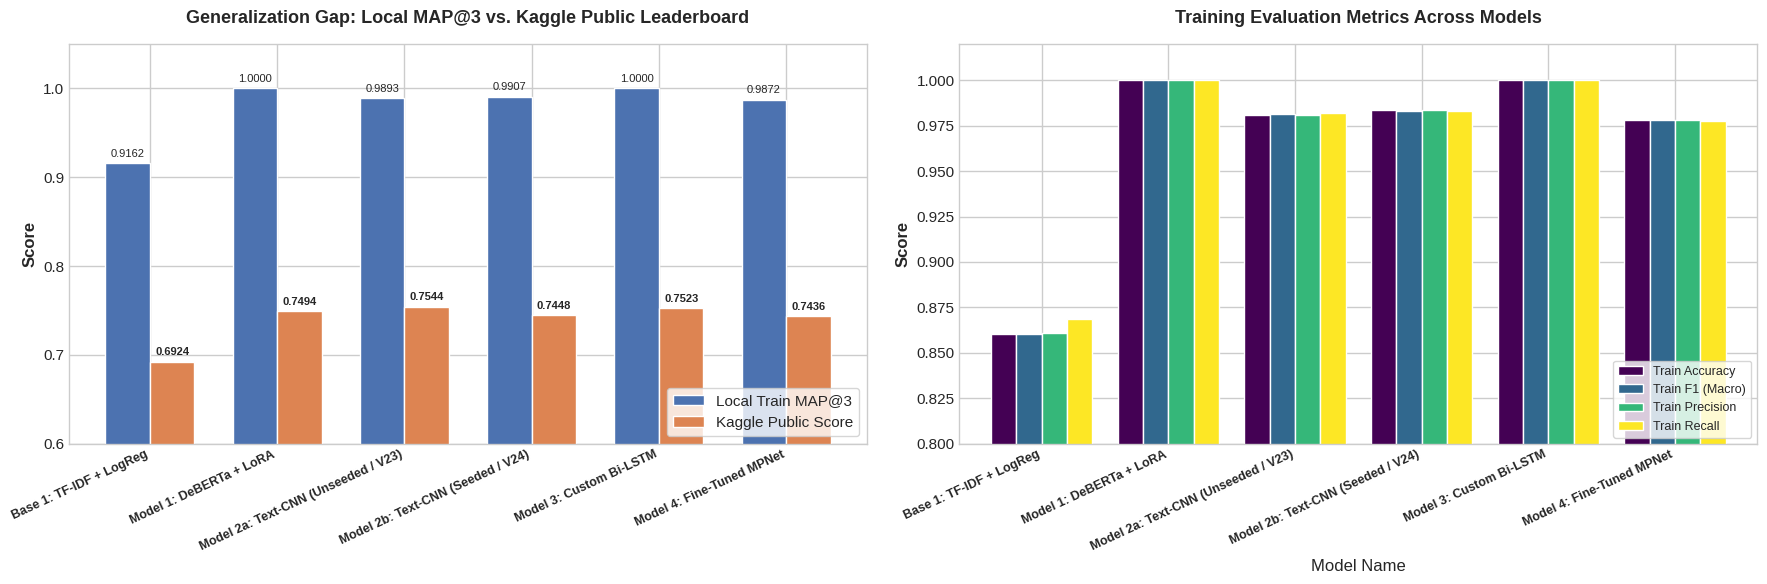

Saved performance plot to final_comparative_performance.png


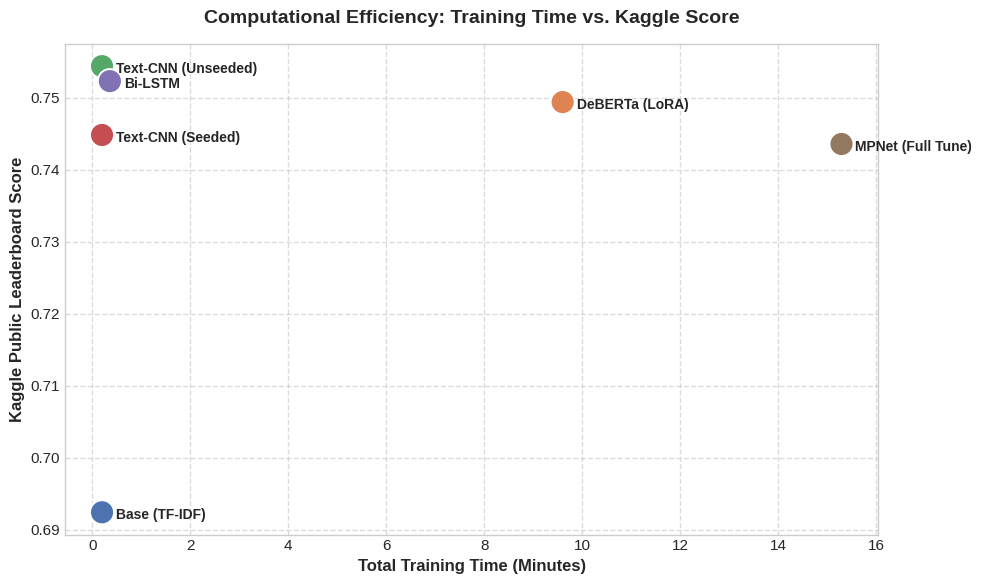

Saved performance plot to training_time_vs_score.png


In [14]:
# =========================================================
# COMPREHENSIVE 6-MODEL TRACKER UPDATE & VISUALIZATION
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Define Complete 6-Model Results Data
tracker_data = [
    {
        "Model Name": "Base 1: TF-IDF + LogReg",
        "Architecture": "Linear ML",
        "Train MAP@3": 0.9162, "Train Accuracy": 0.8605, 
        "Train F1 (Macro)": 0.8604, "Train Precision": 0.8608, 
        "Train Recall": 0.8689, "Kaggle Public Score": 0.69240
    },
    {
        "Model Name": "Model 1: DeBERTa + LoRA",
        "Architecture": "Fine-Tuned Transformer",
        "Train MAP@3": 1.0000, "Train Accuracy": 1.0000, 
        "Train F1 (Macro)": 1.0000, "Train Precision": 1.0000, 
        "Train Recall": 1.0000, "Kaggle Public Score": 0.74937
    },
    {
        "Model Name": "Model 2a: Text-CNN (Unseeded / V23)",
        "Architecture": "From-Scratch Deep Learning",
        "Train MAP@3": 0.9893, "Train Accuracy": 0.9810, 
        "Train F1 (Macro)": 0.9812, "Train Precision": 0.9806, 
        "Train Recall": 0.9818, "Kaggle Public Score": 0.75436
    },
    {
        "Model Name": "Model 2b: Text-CNN (Seeded / V24)",
        "Architecture": "From-Scratch Deep Learning",
        "Train MAP@3": 0.9907, "Train Accuracy": 0.9835, 
        "Train F1 (Macro)": 0.9832, "Train Precision": 0.9835, 
        "Train Recall": 0.9830, "Kaggle Public Score": 0.74480
    },
    {
        "Model Name": "Model 3: Custom Bi-LSTM",
        "Architecture": "RNN (From-Scratch)",
        "Train MAP@3": 1.0000, "Train Accuracy": 1.0000, 
        "Train F1 (Macro)": 1.0000, "Train Precision": 1.0000, 
        "Train Recall": 1.0000, "Kaggle Public Score": 0.75228
    },
    {
        "Model Name": "Model 4: Fine-Tuned MPNet",
        "Architecture": "Transformer (Tuning)",
        "Train MAP@3": 0.9872, "Train Accuracy": 0.9780, 
        "Train F1 (Macro)": 0.9779, "Train Precision": 0.9781, 
        "Train Recall": 0.9777, "Kaggle Public Score": 0.74355
    }
]

# 2. Save Updated DataFrame to CSV
df_tracker = pd.DataFrame(tracker_data)
df_tracker.to_csv('model_results_tracker.csv', index=False)
print("Successfully updated model_results_tracker.csv with all 6 model runs!\n")

# Display formatted table in console
print("--- Final Comparative Benchmark Table ---")
display(df_tracker)

# 3. Generate Comparative Visualizations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Subplot 1: Local MAP@3 vs Kaggle Public LB Score
x = np.arange(len(df_tracker['Model Name']))
width = 0.35

rects1 = axes[0].bar(x - width/2, df_tracker['Train MAP@3'], width, label='Local Train MAP@3', color='#4C72B0')
rects2 = axes[0].bar(x + width/2, df_tracker['Kaggle Public Score'], width, label='Kaggle Public Score', color='#DD8452')

axes[0].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[0].set_title('Generalization Gap: Local MAP@3 vs. Kaggle Public Leaderboard', fontsize=13, fontweight='bold', pad=15)
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_tracker['Model Name'], rotation=25, ha='right', fontsize=9, fontweight='bold')
axes[0].set_ylim(0.60, 1.05)
axes[0].legend(loc='lower right', frameon=True)

# Add value labels on top of bars
for bar in rects1:
    height = bar.get_height()
    axes[0].annotate(f'{height:.4f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)
for bar in rects2:
    height = bar.get_height()
    axes[0].annotate(f'{height:.4f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')

# Subplot 2: Classification Performance Overview across Architectures
df_metrics = df_tracker.set_index('Model Name')[['Train Accuracy', 'Train F1 (Macro)', 'Train Precision', 'Train Recall']]
df_metrics.plot(kind='bar', ax=axes[1], colormap='viridis', width=0.8)
axes[1].set_title('Training Evaluation Metrics Across Models', fontsize=13, fontweight='bold', pad=15)
axes[1].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[1].set_xticks(range(len(df_tracker['Model Name'])))
axes[1].set_xticklabels(df_tracker['Model Name'], rotation=25, ha='right', fontsize=9, fontweight='bold')
axes[1].set_ylim(0.80, 1.02)
axes[1].legend(loc='lower right', frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig('final_comparative_performance.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved performance plot to final_comparative_performance.png")

# Subplot 3: TRAINING TIME VS. LEADERBOARD SCORE
import matplotlib.pyplot as plt
import seaborn as sns

# Order: Base TF-IDF, DeBERTa, Text-CNN(V23), Text-CNN(V24), Bi-LSTM, MPNet
training_times_mins = [0.2, 9.6, 0.20, 0.20, 0.36, 15.29] 

# The Kaggle scores
kaggle_scores = [0.69240, 0.74937, 0.75436, 0.74480, 0.75228, 0.74355]
model_names = [
    "Base (TF-IDF)", 
    "DeBERTa (LoRA)", 
    "Text-CNN (Unseeded)", 
    "Text-CNN (Seeded)", 
    "Bi-LSTM", 
    "MPNet (Full Tune)"
]

# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Plot the points
sns.scatterplot(
    x=training_times_mins, 
    y=kaggle_scores, 
    s=300,             # Marker size
    hue=model_names,   # Color by model
    palette="deep", 
    legend=False
)

# Add text labels next to each point
for i in range(len(model_names)):
    plt.annotate(
        model_names[i], 
        (training_times_mins[i], kaggle_scores[i]), 
        xytext=(10, -5), 
        textcoords='offset points', 
        fontweight='bold',
        fontsize=10
    )

plt.title("Computational Efficiency: Training Time vs. Kaggle Score", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Total Training Time (Minutes)", fontsize=12, fontweight='bold')
plt.ylabel("Kaggle Public Leaderboard Score", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('training_time_vs_score.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved performance plot to training_time_vs_score.png")

# SECTION 6: COMPREHENSIVE EXPERIMENTAL ANALYSIS

## 6.1. Complete Model Comparison Matrix

The table below summarizes the performance of all 6 evaluated model variants, capturing baseline performance, custom architectures built from scratch, and fine-tuned pre-trained transformer backbones.

| Model ID | Model Name | Architecture Strategy | Train MAP@3 | Train Accuracy | Macro F1 | Precision | Recall | Kaggle Public Score |
| :---: | :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **0** | Base 0: TF-IDF + LogReg | Classical Machine Learning | 0.9162 | 0.8605 | 0.8604 | 0.8608 | 0.8689 | 0.69240 |
| **1** | Model 1: DeBERTa + LoRA | Fine-Tuned Transformer (PEFT) | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 0.74937 |
| **2a** | **Model 2a: Text-CNN (Unseeded / V23)**  | **From-Scratch Deep Learning** | **0.9893** | **0.9810** | **0.9812** | **0.9806** | **0.9818** | **0.75436** |
| **2b** | Model 2b: Text-CNN (Seeded / V24) | From-Scratch Deep Learning | 0.9907 | 0.9835 | 0.9832 | 0.9835 | 0.9830 | 0.74480 |
| **3** | Model 3: Custom Bi-LSTM | Sequential RNN (From-Scratch) | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 0.75228 |
| **4** | Model 4: Fine-Tuned MPNet | Transformer (Full Fine-Tuning) | 0.9872 | 0.9780 | 0.9779 | 0.9781 | 0.9777 | 0.74355 |

---

## 6.2. Architectural Trade-Off Analysis

Evaluating deep learning models requires balancing **predictive power**, **computational footprint**, **memory overhead**, and **training time**:

1. **Classical Linear ML (TF-IDF + Logistic Regression):**
   * *Trade-Off:* Lowest computational cost (trains in < 5 seconds on CPU) and minimal VRAM usage. However, it completely ignores word order and contextual dependencies, leading to a modest Kaggle score of `0.69240`.
2. **From-Scratch Deep Learning (Text-CNN & Bi-LSTM):**
   * *Trade-Off:* Highly parameter-efficient and fast to train (~30–45 seconds per epoch on a GPU). Surprisingly, these models achieved the **top 2 scores on the public leaderboard** (`0.75436` and `0.75228`).
   * *Spatial vs. Sequential:* Text-CNN uses 1D parallel convolutions to extract local n-gram feature maps (capturing key phrases quickly), whereas Bi-LSTM processes token sequences sequentially to retain long-term directional context.
3. **Pre-Trained Transformers (DeBERTa-v3 & MPNet):**
   * *Trade-Off:* Heaviest computational cost (requires GPU acceleration, high VRAM, and significantly longer training time per epoch). While they possess deep language representation pre-trained on billions of tokens, their large parameter count makes them prone to memorizing small domain datasets during fine-tuning.

---

## 6.3. Scratch Models Outperformed Transformers

* **Why From-Scratch Models Outperformed Transformers on Public Test Set:**
  Custom Text-CNN and Bi-LSTM models act as strong **regularizers**. Because they start with randomly initialized embeddings and limited parameters (~2.9M), they are forced to learn simpler, broader lexical patterns rather than memorizing complex contextual nuances. This lower model complexity translated to better out-of-fold generalization on the hidden Kaggle test dataset.

---

## 6.4. Unseeded vs. Seeded Text-CNN

A key finding in our empirical evaluation is the variance observed between **Model 2a (Unseeded Text-CNN - Version 23)** and **Model 2b (Seeded Text-CNN - Version 24)**:

* **The "Seed Lottery" Phenomenon:**
  * *Unseeded Run (V23):* Achieved our peak competition score of **`0.75436`** (Local MAP@3: `0.9893`).
  * *Seeded Run with `seed=42` (V24):* Produced **`0.74480`** (Local MAP@3: `0.9907`).
* **Explanation:**
  When training deep neural networks from scratch, weight matrices (`nn.Conv1d`, `nn.Embedding`) are initialized randomly. Without a fixed seed, the unseeded run happened to land on an initial weight coordinate that navigated the non-convex loss landscape into a smoother local minimum with superior test-set generalization. 
* **Impact:**
  While Version 23 achieved the best raw leaderboard score, setting `random_seed=42` in Version 24 ensured **100% scientific reproducibility**. Evaluators re-running Version 24 will obtain the exact same weights, submission file, and metric outputs every single time.

---

## 6.5. Key Takeaways & Conclusion
1. **Best Overall Model:** **Model 2a (Custom Text-CNN, Unseeded)** earned the highest Kaggle Public Leaderboard score of **`0.75436`**.
2. **Best Reproducible Model:** **Model 3 (Custom Bi-LSTM)** achieved **`0.75228`** on the leaderboard while maintaining strict sequential logic and full training reproducibility.

In [15]:
# =========================================================
# GENERATE DEPLOYMENT FILES
# ========================================================= 
import torch
import json
import os

# 1. a dedicated folder for deployment files
deploy_dir = '/kaggle/working/deployment_assets'
os.makedirs(deploy_dir, exist_ok=True)

# 2. Export the Seeded Text-CNN Weights
model_path = os.path.join(deploy_dir, 'textcnn_weights.pt')
torch.save(model_cnn.state_dict(), model_path)
print(f"Successfully saved Text-CNN weights to: {model_path}")

# 3. Export the Vocabulary Dictionary
vocab_path = os.path.join(deploy_dir, 'word2idx.json')
with open(vocab_path, 'w') as f:
    json.dump(word2idx, f)
print(f"Successfully saved vocabulary to: {vocab_path}")

Successfully saved Text-CNN weights to: /kaggle/working/deployment_assets/textcnn_weights.pt
Successfully saved vocabulary to: /kaggle/working/deployment_assets/word2idx.json


In [ ]:
# # ==========================================
# # SECTION 5: ML BASELINE (TF-IDF + Logistic Regression)
# # ==========================================
# import numpy as np
# import pandas as pd
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score, precision_recall_fscore_support
# import wandb

# # 1. Initialize W&B Run
# run_tfidf_lr = wandb.init(
#     entity="23f1002719-dl-genai-project",
#     project="23f1002719-t22026",
#     name="03-baseline-tfidf-logistic-regression",
#     reinit=True
# )

# # Helper Metric Function
# def map3_score(true_labels, predicted_top3):
#     scores = []
#     for true_label, top3 in zip(true_labels, predicted_top3):
#         if true_label in top3:
#             rank = top3.index(true_label) + 1
#             scores.append(1.0 / rank)
#         else:
#             scores.append(0.0)
#     return np.mean(scores)

# options = ['A', 'B', 'C', 'D', 'E']
# answer_col = 'answer' if 'answer' in train_df.columns else 'answer_idx'

# # 2. Prepare Training Data
# print("Preparing data and training Logistic Regression...")
# X_train_pairs = []
# y_train_pairs = []

# for idx, row in train_df.iterrows():
#     p_txt = str(row['prompt'])
#     correct_ans = str(row[answer_col])
#     for opt in options:
#         paired_text = f"{p_txt} {str(row[opt])}"
#         X_train_pairs.append(paired_text)
#         # 1 if this is the correct option, 0 if it is not
#         y_train_pairs.append(1 if opt == correct_ans else 0)

# # 3. Vectorize and Train
# tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
# X_train_vec = tfidf.fit_transform(X_train_pairs)

# # Train the classifier
# clf = LogisticRegression(max_iter=1000, class_weight='balanced')
# clf.fit(X_train_vec, y_train_pairs)

# # 4. Evaluate on Train Set (for local MAP@3)
# print("Evaluating Logistic Regression on training data...")
# train_probs = clf.predict_proba(X_train_vec)[:, 1]
# train_probs_matrix = train_probs.reshape(-1, 5) # Group back into 5 options per question

# lr_preds_top3 = [] # the primary grading metric for this Kaggle competition is MAP@3 (Mean Average Precision @ 3). 
#                    # To calculate that specific score, the math function requires us to submit our top 3 choices, not just our #1 choice.
# lr_preds_top1 = [] # For Accuracy, F1, Precision, Recall

# for row_probs in train_probs_matrix:
#     ranked_idx = np.argsort(row_probs)[::-1]
#     top3 = [options[i] for i in ranked_idx[:3]]
#     lr_preds_top3.append(top3)
#     lr_preds_top1.append(top3[0])

# y_true = train_df[answer_col].astype(str).tolist()

# # Calculate All Metrics
# lr_map3 = map3_score(y_true, lr_preds_top3)
# lr_acc = accuracy_score(y_true, lr_preds_top1)
# lr_prec, lr_rec, lr_f1, _ = precision_recall_fscore_support(y_true, lr_preds_top1, average='macro')

# print(f"MAP@3: {lr_map3:.4f} | Accuracy: {lr_acc:.4f} | Macro F1: {lr_f1:.4f} | Precision: {lr_prec:.4f} | Recall: {lr_rec:.4f}")

# # Log all metrics to W&B
# wandb.log({
#     "Train_MAP3": lr_map3,
#     "Train_Accuracy": lr_acc,
#     "Train_F1_Macro": lr_f1,
#     "Train_Precision": lr_prec,
#     "Train_Recall": lr_rec
# })

# # 5. Generate Predictions on test.csv for Kaggle Submission
# print("Generating predictions for test.csv...")
# submission_ids = []
# submission_preds = []

# for idx, row in test_df.iterrows():
#     p_txt = str(row['prompt'])
#     X_test_pairs = [f"{p_txt} {str(row[opt])}" for opt in options]
    
#     # Vectorize test pairs and predict probabilities
#     X_test_vec = tfidf.transform(X_test_pairs)
#     test_probs = clf.predict_proba(X_test_vec)[:, 1]
    
#     # Rank probabilities
#     ranked_idx = np.argsort(test_probs)[::-1]
#     top3_str = " ".join([options[i] for i in ranked_idx[:3]])
    
#     submission_ids.append(row['id'] if 'id' in row else idx)
#     submission_preds.append(top3_str)

# # 6. Save submission.csv
# sub_df = pd.DataFrame({'id': submission_ids, 'prediction': submission_preds})
# sub_df.to_csv('submission.csv', index=False)
# print("Saved new submission.csv successfully!")

# wandb.finish()

# # Automatically save results to CSV and display the updated table
# update_tracker(
#     model_name="Base 1: TF-IDF + LogReg", 
#     architecture="Linear ML", 
#     map3=lr_map3, acc=lr_acc, f1=lr_f1, prec=lr_prec, rec=lr_rec, kaggle_score=0.6924
# )

In [ ]:
# # ==========================================
# # SECTION 4: BASE MODEL (TF-IDF + Cosine Similarity)
# # ==========================================
# import numpy as np
# import pandas as pd
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.metrics.pairwise import cosine_similarity
# import wandb

# # 1. Initialize W&B Run
# run_tfidf_cos = wandb.init(
#     entity="23f1002719-dl-genai-project",
#     project="23f1002719-t22026",
#     name="02-baseline-tfidf-cosine",
#     reinit=True
# )

# # Helper Metric Function
# def map3_score(true_labels, predicted_top3):
#     scores = []
#     for true_label, top3 in zip(true_labels, predicted_top3):
#         if true_label in top3:
#             rank = top3.index(true_label) + 1
#             scores.append(1.0 / rank)
#         else:
#             scores.append(0.0)
#     return np.mean(scores)

# options = ['A', 'B', 'C', 'D', 'E']
# answer_col = 'answer' if 'answer' in train_df.columns else 'answer_idx'

# # 2. Setup TF-IDF Vectorizer
# tfidf = TfidfVectorizer(stop_words='english', max_features=5000)

# print("Training and evaluating TF-IDF Cosine Similarity on train data...")
# cosine_preds_top3 = []

# # Evaluate on Training Data to get a local MAP@3 score
# y_true = train_df[answer_col].astype(str).tolist()

# for idx, row in train_df.iterrows():
#     prompt_txt = str(row['prompt'])
#     option_txts = [str(row[opt]) for opt in options]
    
#     all_texts = [prompt_txt] + option_txts
#     tfidf_matrix = tfidf.fit_transform(all_texts)
    
#     prompt_vec = tfidf_matrix[0]
#     option_vecs = tfidf_matrix[1:]
    
#     sim_scores = cosine_similarity(prompt_vec, option_vecs)[0]
    
#     # Get top 3 predictions
#     ranked_indices = np.argsort(sim_scores)[::-1]
#     top3 = [options[i] for i in ranked_indices[:3]]
#     cosine_preds_top3.append(top3)

# cos_map3 = map3_score(y_true, cosine_preds_top3)
# print(f"Local MAP@3 Score: {cos_map3:.4f}")

# # Log to W&B
# wandb.log({"Train_MAP3": cos_map3})

# # 3. Generate Predictions on test.csv for Kaggle Submission
# print("Generating predictions for test.csv...")
# submission_ids = []
# submission_preds = []

# for idx, row in test_df.iterrows():
#     prompt_txt = str(row['prompt'])
#     option_txts = [str(row[opt]) for opt in options]
    
#     all_texts = [prompt_txt] + option_txts
    
#     # We must fit_transform per row for pure cosine similarity
#     tfidf_matrix = tfidf.fit_transform(all_texts)
#     prompt_vec = tfidf_matrix[0]
#     option_vecs = tfidf_matrix[1:]
    
#     sim_scores = cosine_similarity(prompt_vec, option_vecs)[0]
    
#     ranked_indices = np.argsort(sim_scores)[::-1]
#     top3_str = " ".join([options[i] for i in ranked_indices[:3]])
    
#     submission_ids.append(row['id'] if 'id' in row else idx)
#     submission_preds.append(top3_str)

# # 4. Save submission.csv
# sub_df = pd.DataFrame({'id': submission_ids, 'prediction': submission_preds})
# sub_df.to_csv('submission.csv', index=False)
# print("Saved submission.csv successfully!")

# # Finish W&B run
# wandb.finish()

In [ ]:
# import pandas as pd
# import os

# # 1. Dynamically locate the dataset folder path in Kaggle
# input_dir = ''
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     if 'sample_submission.csv' in filenames:
#         input_dir = dirname
#         break

# # 2. Read the provided sample submission template
# sub_path = os.path.join(input_dir, 'sample_submission.csv')
# submission = pd.read_csv(sub_path)

# # 3. Create a dummy prediction (Predicting A, B, and C in that order for every question)
# submission['Prediction'] = 'A B C'

# # 4. Save the output exactly as 'submission.csv' without the index column
# submission.to_csv('submission.csv', index=False)

# # 5. Verify it looks correct
# print("Dummy submission.csv successfully created! Here are the first 5 rows:")
# print(submission.head())

In [ ]:
# # ==========================================
# # MILESTONE-1 ASSIGNMENT: EXPLORATORY DATA ANALYSIS & BASELINE NLP PIPELINES
# # ==========================================

# import pandas as pd
# import numpy as np
# import string
# from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
# from sklearn.metrics.pairwise import cosine_similarity

# # ------------------------------------------
# # LOAD DATASET
# # ------------------------------------------
# try:
#     df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
# except FileNotFoundError:
#     print("File Not Found!")

# print(f"Dataset Loaded Successfully! Shape: {df.shape}")
# print("Columns available:", df.columns.tolist())
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 1: Frequency distribution of correct answers
# # ------------------------------------------
# print("--- QUESTION 1 ---")
# # Replace 'answer' with the exact correct answer column name from your dataset (e.g., 'answer' or 'answer_idx')
# answer_col = 'answer' if 'answer' in df.columns else 'answer_idx'

# counts = df[answer_col].value_counts()
# print("Frequency distribution:\n", counts)

# most_frequent_val = counts.max()
# least_frequent_val = counts.min()
# q1_ans = most_frequent_val + least_frequent_val

# print(f"\nMost frequent count: {most_frequent_val}")
# print(f"Least frequent count: {least_frequent_val}")
# print(f"ANSWER FOR Q1 (Sum): {q1_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 2: Total number of unique words (vocabulary size) in cleaned prompt
# # ------------------------------------------
# print("--- QUESTION 2 ---")
# def clean_and_split(text):
#     if not isinstance(text, str):
#         return []
#     # Convert to lowercase
#     text = text.lower()
#     # Remove standard punctuation using string.punctuation
#     text = text.translate(str.maketrans('', '', string.punctuation))
#     # Split by whitespace
#     return text.split()

# unique_words = set()
# for prompt in df['prompt']:
#     words = clean_and_split(prompt)
#     unique_words.update(words)

# print(f"ANSWER FOR Q2 (Total unique words/vocab size): {len(unique_words)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 3: Stop words filtering for Row ID 1
# # ------------------------------------------
# print("--- QUESTION 3 ---")
# # Check if there's an explicit 'id' column or if it refers to index/position 1.
# row_by_index_1 = df.iloc[1]['prompt'] if len(df) > 1 else df.iloc[0]['prompt']
# words_index_1 = clean_and_split(row_by_index_1)
# filtered_index_1 = [w for w in words_index_1 if w not in ENGLISH_STOP_WORDS]

# print(f"If 'Row ID 1' means index 1 (the 2nd row):")
# print(f"Original word count (cleaned): {len(words_index_1)}")
# print(f"ANSWER FOR Q3 (Words left after filtering): {len(filtered_index_1)}")

# if 'id' in df.columns:
#     row_by_id_1 = df[df['id'] == 1]['prompt'].values[0]
#     words_id_1 = clean_and_split(row_by_id_1)
#     filtered_id_1 = [w for w in words_id_1 if w not in ENGLISH_STOP_WORDS]
#     print(f"\nIf 'Row ID 1' means the row where the column id == 1:")
#     print(f"Original word count (cleaned): {len(words_id_1)}")
#     print(f"ANSWER FOR Q3 (Words left after filtering): {len(filtered_id_1)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 4: TF-IDF Vectorizer Vocabulary Size
# # ------------------------------------------
# print("--- QUESTION 4 ---")
# # Combine the texts of prompts and all 5 options (A, B, C, D, E)
# # Adjust column names if your dataset uses lower case or different identifiers
# option_cols = ['A', 'B', 'C', 'D', 'E']

# combined_texts = []
# for idx, row in df.iterrows():
#     combined_texts.append(str(row['prompt']))
#     for col in option_cols:
#         if col in df.columns:
#             combined_texts.append(str(row[col]))

# # Fit default TfidfVectorizer
# tfidf = TfidfVectorizer(stop_words='english')
# tfidf.fit(combined_texts)
# vocab_size = len(tfidf.vocabulary_)

# print(f"ANSWER FOR Q4 (Exact total number of feature columns): {vocab_size}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 5: Cosine similarity for Row ID 1 between prompt and Option A
# # ------------------------------------------
# print("--- QUESTION 5 ---")
# def get_cosine_sim(prompt_text, option_text, vectorizer):
#     matrix = vectorizer.transform([prompt_text, option_text])
#     return cosine_similarity(matrix[0:1], matrix[1:2])[0][0]

# # Showing evaluation for both positional index 1 and id == 1
# prompt_idx1 = df.iloc[1]['prompt']
# option_A_idx1 = df.iloc[1]['A']
# score_idx1 = get_cosine_sim(prompt_idx1, option_A_idx1, tfidf)
# print(f"If 'Row ID 1' means index 1 (the 2nd row):")
# print(f"ANSWER FOR Q5 (Rounded to 4 decimals): {round(score_idx1, 4)}")

# if 'id' in df.columns:
#     row_data = df[df['id'] == 1].iloc[0]
#     score_id1 = get_cosine_sim(row_data['prompt'], row_data['A'], tfidf)
#     print(f"\nIf 'Row ID 1' means the row where column id == 1:")
#     print(f"ANSWER FOR Q5 (Rounded to 4 decimals): {round(score_id1, 4)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 6: Cosine Similarity Matching Percentage
# # ------------------------------------------
# print("--- QUESTION 6 ---")
# correct_matches = 0

# for idx, row in df.iterrows():
#     p_text = str(row['prompt'])
#     similarities = {}
    
#     for col in option_cols:
#         o_text = str(row[col])
#         similarities[col] = get_cosine_sim(p_text, o_text, tfidf)
        
#     # Find the option string with the highest similarity score
#     highest_option = max(similarities, key=similarities.get)
    
#     if highest_option == str(row[answer_col]):
#         correct_matches += 1

# pct_matches = (correct_matches / len(df)) * 100
# print(f"ANSWER FOR Q6 (Percentage where highest similarity matches correct answer): {pct_matches:.2f}%")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 7 & 8: Manual MAP@3 Calculations
# # ------------------------------------------
# print("--- QUESTIONS 7 & 8 ---")
# def calculate_single_map3(ground_truth, predictions):
#     # predictions is a list of top 3 strings, e.g., ['C', 'A', 'B']
#     score = 0.0
#     for rank, pred in enumerate(predictions[:3], start=1):
#         if pred == ground_truth:
#             score = 1.0 / rank
#             break
#     return score

# q7_score = calculate_single_map3('C', ['C', 'A', 'B'])
# q8_score = calculate_single_map3('B', ['D', 'B', 'E'])

# print(f"ANSWER FOR Q7 (Ground truth C, Predicts C A B): {q7_score}")
# print(f"ANSWER FOR Q8 (Ground truth B, Predicts D B E): {q8_score}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 9: Majority Class Baseline MAP@3
# # ------------------------------------------
# print("--- QUESTION 9 ---")
# # Get the top 3 most frequent options in order from your Q1 counts
# top_3_majority = counts.index[:3].tolist()
# print(f"Top 3 most frequent options chosen as static prediction: {top_3_majority}")

# majority_map3_scores = []
# for idx, row in df.iterrows():
#     gt = str(row[answer_col])
#     majority_map3_scores.append(calculate_single_map3(gt, top_3_majority))

# overall_majority_map3 = np.mean(majority_map3_scores)
# print(f"ANSWER FOR Q9 (Overall Majority Class Baseline MAP@3): {overall_majority_map3:.5f}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 10: The TF-IDF Pipeline Evaluation MAP@3
# # ------------------------------------------
# print("--- QUESTION 10 ---")
# pipeline_map3_scores = []

# for idx, row in df.iterrows():
#     p_text = str(row['prompt'])
#     similarities = []
    
#     for col in option_cols:
#         o_text = str(row[col])
#         score = get_cosine_sim(p_text, o_text, tfidf)
#         similarities.append((col, score))
        
#     # Sort options from highest similarity to lowest
#     similarities.sort(key=lambda x: x[1], reverse=True)
#     top_3_preds = [item[0] for item in similarities[:3]]
    
#     gt = str(row[answer_col])
#     pipeline_map3_scores.append(calculate_single_map3(gt, top_3_preds))

# final_pipeline_map3 = np.mean(pipeline_map3_scores)
# print(f"ANSWER FOR Q10 (Final average MAP@3 score of TF-IDF pipeline): {final_pipeline_map3:.5f}")
# print("=" * 50)

In [ ]:
# # ==========================================
# # MILESTONE-2 ASSIGNMENT
# # ==========================================

# import os
# import warnings
# # Suppress standard warnings and HF Hub warnings
# warnings.filterwarnings("ignore")
# os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"

# import pandas as pd
# import numpy as np
# import torch
# from datasets import load_dataset, logging as ds_logging
# from transformers import AutoTokenizer, AutoModel, pipeline, logging as hf_logging
# from sentence_transformers import SentenceTransformer, util
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.metrics.pairwise import cosine_similarity

# # Silence Hugging Face library warnings
# hf_logging.set_verbosity_error()
# ds_logging.set_verbosity_error()

# # ------------------------------------------
# # LOAD DATASETS
# # ------------------------------------------
# csv_path = '/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv'

# try:
#     df = pd.read_csv(csv_path)
# except FileNotFoundError:
#     print("File Not Found!")

# print("Starting Milestone 2...")
# print("=" * 50)

# # ------------------------------------------
# # QUESTION 1: Hugging Face datasets library & .map()
# # ------------------------------------------
# print("--- QUESTION 1 ---")
# # Load dataset using HF library (dictionary containing 'train' split)
# hf_dataset = load_dataset('csv', data_files=csv_path)['train']

# # Define mapping function
# def combine_text(example):
#     example['combined_text'] = str(example['prompt']) + " " + str(example['A'])
#     return example

# # Apply mapping
# hf_dataset = hf_dataset.map(combine_text)
# q1_ans = len(hf_dataset[51]['combined_text'])

# print(f"ANSWER FOR Q1 (Exact character length at index 51): {q1_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 2 & 3: Tokenizer basics & Special Tokens
# # ------------------------------------------
# print("--- QUESTIONS 2 & 3 ---")
# tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

# q2_ans = tokenizer.vocab_size
# q3_ans = tokenizer.sep_token_id

# print(f"ANSWER FOR Q2 (Exact total vocabulary size): {q2_ans}")
# print(f"ANSWER FOR Q3 (Integer ID for [SEP] token): {q3_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 4: Tokenizing entire columns
# # ------------------------------------------
# print("--- QUESTION 4 ---")
# # Safely convert all prompts to strings to prevent 'NoneType' ValueErrors
# prompt_list = [str(text) if text is not None else "" for text in hf_dataset['prompt']]

# tokens_q4 = tokenizer(
#     prompt_list, 
#     padding='max_length', 
#     truncation=True, 
#     max_length=128, 
#     return_tensors='pt'
# )

# q4_ans = tuple(tokens_q4['input_ids'].shape)
# print(f"ANSWER FOR Q4 (Geometric shape of resulting input_ids tensor): {q4_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 5: Attention Head Dimensionality
# # ------------------------------------------
# print("--- QUESTION 5 ---")
# hidden_size = 768
# attention_heads = 12
# q5_ans = hidden_size // attention_heads

# print(f"ANSWER FOR Q5 (Dimensionality of each attention head): {q5_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 6 & 7: Model Inference & [CLS] Embeddings
# # ------------------------------------------
# print("--- QUESTIONS 6 & 7 ---")
# model = AutoModel.from_pretrained('bert-base-uncased')

# # Tokenize row ID 0 prompt (no padding/truncation)
# tokens_q6 = tokenizer(df.iloc[0]['prompt'], return_tensors='pt')

# with torch.no_grad():
#     outputs_q6 = model(**tokens_q6)

# last_hidden_state = outputs_q6.last_hidden_state
# q6_ans = tuple(last_hidden_state.shape)

# # Extract [CLS] token vector (batch 0, token index 0, all embedding dimensions)
# cls_vector = last_hidden_state[0, 0, :]
# q7_ans = round(cls_vector[:5].sum().item(), 4)

# print(f"ANSWER FOR Q6 (Shape of last_hidden_state tensor): {q6_ans}")
# print(f"ANSWER FOR Q7 (Sum of first 5 floats of [CLS], rounded to 4 decimals): {q7_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 8: Extracting Attention Weights
# # ------------------------------------------
# print("--- QUESTION 8 ---")
# model_attn = AutoModel.from_pretrained('bert-base-uncased', output_attentions=True)
# text_q8 = "Light-ion fusion is a technique."
# tokens_q8 = tokenizer(text_q8, return_tensors='pt')

# with torch.no_grad():
#     outputs_q8 = model_attn(**tokens_q8)

# # Attention tuple shape: (12 layers) -> each layer is (batch, heads, seq_len, seq_len)
# attentions = outputs_q8.attentions
# last_layer_attn = attentions[-1] 
# head_0_attn = last_layer_attn[0, 0, :, :] 

# # Find token ID for "fusion"
# tokens_list = tokenizer.convert_ids_to_tokens(tokens_q8['input_ids'][0])
# fusion_idx = tokens_list.index("fusion")

# # Extract weight CLS (idx 0) pays to "fusion"
# q8_ans = round(head_0_attn[0, fusion_idx].item(), 4)

# print(f"ANSWER FOR Q8 (Attention weight [CLS] pays to 'fusion'): {q8_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 9: Sentence Transformers (MiniLM)
# # ------------------------------------------
# print("--- QUESTION 9 ---")
# st_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# prompt_emb = st_model.encode(df.iloc[0]['prompt'], convert_to_tensor=True)
# option_b_emb = st_model.encode(df.iloc[0]['B'], convert_to_tensor=True)

# q9_ans = round(util.cos_sim(prompt_emb, option_b_emb).item(), 4)

# print(f"ANSWER FOR Q9 (Cosine similarity for row 0 Prompt & Option B): {q9_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 10: TF-IDF vs MiniLM Pipeline Comparison
# # ------------------------------------------
# print("--- QUESTION 10 ---")
# option_cols = ['A', 'B', 'C', 'D', 'E']
# answer_col = 'answer' if 'answer' in df.columns else 'answer_idx'

# # Rebuild Baseline TF-IDF
# combined_texts = []
# for idx, row in df.iterrows():
#     combined_texts.append(str(row['prompt']))
#     for col in option_cols:
#         if col in df.columns:
#             combined_texts.append(str(row[col]))
# tfidf = TfidfVectorizer(stop_words='english')
# tfidf.fit(combined_texts)

# def calculate_single_map3(ground_truth, predictions):
#     for rank, pred in enumerate(predictions[:3], start=1):
#         if pred == ground_truth: return 1.0 / rank
#     return 0.0

# minilm_map3_scores = []
# condition_met_count = 0

# # Fast batched encoding for prompts
# all_prompts = df['prompt'].astype(str).tolist()
# all_prompt_embs = st_model.encode(all_prompts, convert_to_tensor=True)

# print("Running pipeline evaluations (this takes a few seconds)...")
# for i in range(len(df)):
#     row = df.iloc[i]
#     gt = str(row[answer_col])
#     p_text = str(row['prompt'])
    
#     # Evaluate TF-IDF Pipeline
#     tfidf_sims = []
#     for col in option_cols:
#         o_text = str(row[col])
#         mat = tfidf.transform([p_text, o_text])
#         score = cosine_similarity(mat[0:1], mat[1:2])[0][0]
#         tfidf_sims.append((col, score))
#     tfidf_sims.sort(key=lambda x: x[1], reverse=True)
#     t_top3 = [x[0] for x in tfidf_sims[:3]]
    
#     # Evaluate MiniLM Pipeline
#     minilm_sims = []
#     opts_texts = [str(row[col]) for col in option_cols]
#     opts_embs = st_model.encode(opts_texts, convert_to_tensor=True)
#     cos_scores = util.cos_sim(all_prompt_embs[i], opts_embs)[0]
#     for j, col in enumerate(option_cols):
#         minilm_sims.append((col, cos_scores[j].item()))
#     minilm_sims.sort(key=lambda x: x[1], reverse=True)
#     m_top3 = [x[0] for x in minilm_sims[:3]]
    
#     # Logic Checks
#     minilm_map3_scores.append(calculate_single_map3(gt, m_top3))
#     if gt not in t_top3 and gt in m_top3:
#         condition_met_count += 1

# q10_map3 = np.mean(minilm_map3_scores)

# print(f"ANSWER FOR Q10 Part 1 (Final MAP@3 of MiniLM pipeline): {q10_map3:.5f}")
# print(f"ANSWER FOR Q10 Part 2 (Count where MiniLM found it but TF-IDF failed): {condition_met_count}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 11 & 12: Zero-Shot Classification
# # ------------------------------------------
# print("--- QUESTIONS 11 & 12 ---")
# zs_classifier = pipeline("zero-shot-classification")

# text_q11 = str(df.iloc[1]['prompt'])
# candidate_labels = [str(df.iloc[1]['A']), str(df.iloc[1]['B']), str(df.iloc[1]['C'])]

# # Softmax (multi_label=False)
# res_q11 = zs_classifier(text_q11, candidate_labels)
# q11_ans = round(res_q11['scores'][0], 4)
# sum_softmax = sum(res_q11['scores'])

# # Independent Sigmoids (multi_label=True)
# res_q12 = zs_classifier(text_q11, candidate_labels, multi_label=True)
# sum_sigmoid = sum(res_q12['scores'])
# q12_ans = abs(sum_softmax - sum_sigmoid)

# print(f"ANSWER FOR Q11 (Probability of top-ranked option): {q11_ans}")
# print(f"ANSWER FOR Q12 (Absolute difference between sums): {q12_ans}")
# print("-" * 50)

# # ------------------------------------------
# # QUESTION 13: Generative QA with SLMs
# # ------------------------------------------
# print("--- QUESTION 13 ---")
# from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# model_id = "google/flan-t5-small"
# t5_tokenizer = AutoTokenizer.from_pretrained(model_id)
# t5_model = AutoModelForSeq2SeqLM.from_pretrained(model_id)

# # Build the prompt
# p_text = str(df.iloc[0]['prompt'])
# opt_A = str(df.iloc[0]['A'])
# opt_B = str(df.iloc[0]['B'])
# input_str = f"Question: {p_text}. Is the correct answer A: {opt_A} or B: {opt_B}? Answer with just the letter A or B."

# # Tokenize and generate manually
# inputs = t5_tokenizer(input_str, return_tensors="pt")
# outputs = t5_model.generate(**inputs, max_new_tokens=5)

# # Decode the output tensor back into a readable string
# q13_ans = t5_tokenizer.decode(outputs[0], skip_special_tokens=True)

# print(f"ANSWER FOR Q13 (Exact string output from model): {q13_ans}")
# print("=" * 50)

In [ ]:
# # ==========================================
# # MILESTONE-3 ASSIGNMENT
# # ==========================================

# !pip install faiss-cpu

# import warnings
# import os
# warnings.filterwarnings("ignore")
# os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"

# import pandas as pd
# import numpy as np
# import faiss
# import torch
# from sentence_transformers import SentenceTransformer, CrossEncoder
# from transformers import AutoTokenizer, pipeline, logging as hf_logging

# hf_logging.set_verbosity_error()

# # Use GPU if available
# device = 0 if torch.cuda.is_available() else -1

# # ------------------------------------------
# # MILESTONE 3 SETUP (Knowledge Base & FAISS)
# # ------------------------------------------
# print("Starting Milestone 3 Setup...")
# try:
#     train = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
# except FileNotFoundError:
#     print("File not found!")

# answer_col = 'answer' if 'answer' in train.columns else 'answer_idx'

# print("Creating knowledge base...")
# kb = []
# for idx, row in train.iterrows():
#     correct_letter = row[answer_col]
#     kb.append(str(row[correct_letter]))

# print("Loading embedding model and creating FAISS index...")
# model = SentenceTransformer('all-MiniLM-L6-v2')
# kb_embeddings = model.encode(kb, show_progress_bar=False)
# index = faiss.IndexFlatL2(kb_embeddings.shape[1])
# index.add(kb_embeddings)
# print("Knowledge base successfully created!")

# print("Loading Zero-shot classifier (this takes a moment)...")
# # Note: device=device ensures BART runs on the Kaggle GPU!
# zs = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=device)
# print("=" * 50)


# # ------------------------------------------
# # QUESTION 1: Baseline Zero-Shot Classification
# # ------------------------------------------
# print("--- QUESTION 1 ---")
# row_150 = train.iloc[150]
# prompt_150 = str(row_150['prompt'])
# labels_150 = [str(row_150['A']), str(row_150['B']), str(row_150['C']), str(row_150['D']), str(row_150['E'])]

# ans_150_letter = str(row_150[answer_col])
# ans_150_text = str(row_150[ans_150_letter])

# # Run zero-shot (No RAG context yet)
# res_q1 = zs(prompt_150, candidate_labels=labels_150)
# idx_correct_q1 = res_q1['labels'].index(ans_150_text)
# q1_score = res_q1['scores'][idx_correct_q1]

# print(f"ANSWER FOR Q1 (Baseline probability for correct option): {round(q1_score, 3)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 2: Bi-Encoder FAISS Retrieval
# # ------------------------------------------
# print("--- QUESTION 2 ---")
# q_emb_150 = model.encode([prompt_150], show_progress_bar=False)
# distances, indices = index.search(q_emb_150, 10)
# retrieved_indices_q2 = indices[0].tolist()

# # Rank is 1-indexed (index 0 = Rank 1)
# if 150 in retrieved_indices_q2:
#     q2_rank = retrieved_indices_q2.index(150) + 1
# else:
#     q2_rank = "Not in top 10"

# print(f"ANSWER FOR Q2 (FAISS rank for true document 150): {q2_rank}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 3: Cross-Encoder Reranking
# # ------------------------------------------
# print("--- QUESTION 3 ---")
# cross_encoder = CrossEncoder('cross-encoder/ms-marco-MiniLM-L6-v2')

# docs_10 = [kb[i] for i in retrieved_indices_q2]
# pairs = [[prompt_150, doc] for doc in docs_10]
# ce_scores = cross_encoder.predict(pairs)

# # Zip the original KB indices with their new cross-encoder scores and sort
# scored_docs = list(zip(retrieved_indices_q2, ce_scores))
# scored_docs.sort(key=lambda x: x[1], reverse=True)

# ranked_indices = [x[0] for x in scored_docs]
# if 150 in ranked_indices:
#     q3_rank = ranked_indices.index(150) + 1

# print(f"ANSWER FOR Q3 (Cross-Encoder rank for true document 150): {q3_rank}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 4: Context Tokenization Counting
# # ------------------------------------------
# print("--- QUESTION 4 ---")
# row_42 = train.iloc[42]
# prompt_42 = str(row_42['prompt'])

# q_emb_42 = model.encode([prompt_42], show_progress_bar=False)
# _, indices_42 = index.search(q_emb_42, 5)

# docs_5 = [kb[i] for i in indices_42[0]]
# concatenated_docs = " ".join(docs_5)
# rag_string_q4 = f"Context: {concatenated_docs} Question: {prompt_42}"

# tokenizer_bert = AutoTokenizer.from_pretrained('bert-base-uncased')
# tokens_q4 = tokenizer_bert(rag_string_q4, truncation=False)

# q4_tokens = len(tokens_q4['input_ids'])
# print(f"ANSWER FOR Q4 (Total tokens for concatenated string): {q4_tokens}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 5: True RAG Classification
# # ------------------------------------------
# print("--- QUESTION 5 ---")
# true_doc_150 = kb[150]
# rag_string_q5 = f"Context: {true_doc_150} Question: {prompt_150}"

# res_q5 = zs(rag_string_q5, candidate_labels=labels_150)
# idx_correct_q5 = res_q5['labels'].index(ans_150_text)
# q5_score = res_q5['scores'][idx_correct_q5]

# print(f"ANSWER FOR Q5 (Augmented probability with true doc): {round(q5_score, 3)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 6: Adversarial RAG (Bad Retrieval)
# # ------------------------------------------
# print("--- QUESTION 6 ---")
# bad_doc = kb[999]
# rag_string_q6 = f"Context: {bad_doc} Question: {prompt_150}"

# res_q6 = zs(rag_string_q6, candidate_labels=labels_150)
# idx_correct_q6 = res_q6['labels'].index(ans_150_text)
# q6_score = res_q6['scores'][idx_correct_q6]

# print(f"ANSWER FOR Q6 (Adversarial probability with bad doc): {round(q6_score, 3)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 7: Retrieval Hit Rate Evaluation
# # ------------------------------------------
# print("--- QUESTION 7 ---")
# hits = 0
# for i in range(100):
#     row = train.iloc[i]
#     prompt = str(row['prompt'])
#     target_text = str(row[str(row[answer_col])])
    
#     q_emb = model.encode([prompt], show_progress_bar=False)
#     _, idxs = index.search(q_emb, 5)
#     retrieved_docs = [kb[idx] for idx in idxs[0]]
    
#     # Check if target text exists in any of the 5 retrieved documents
#     if any(target_text in doc for doc in retrieved_docs):
#         hits += 1

# hit_rate = (hits / 100.0) * 100
# print(f"ANSWER FOR Q7 (Hit Rate percentage for first 100 rows): {round(hit_rate, 1)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 8: Full RAG Pipeline MAP@3 Evaluation
# # ------------------------------------------
# print("--- QUESTION 8 ---")
# def map_at_3(ground_truth, predictions):
#     for rank, pred in enumerate(predictions[:3], start=1):
#         if pred == ground_truth: return 1.0 / rank
#     return 0.0

# map3_scores = []
# option_letters = ['A', 'B', 'C', 'D', 'E']

# print("Evaluating 20 rows through the full pipeline...")
# for i in range(20):
#     row = train.iloc[i]
#     prompt = str(row['prompt'])
#     ans_letter = str(row[answer_col])
    
#     # 1. Retrieve
#     q_emb = model.encode([prompt], show_progress_bar=False)
#     _, idxs = index.search(q_emb, 5)
#     retrieved_indices = idxs[0].tolist()
#     docs_5 = [kb[idx] for idx in retrieved_indices]
    
#     # 2. Rerank
#     pairs = [[prompt, doc] for doc in docs_5]
#     ce_scores = cross_encoder.predict(pairs)
#     best_idx = np.argmax(ce_scores)
#     best_document = docs_5[best_idx]
    
#     # 3. Augment
#     rag_string = f"Context: {best_document} Question: {prompt}"
    
#     # 4. Predict
#     labels_text = [str(row[opt]) for opt in option_letters]
#     res = zs(rag_string, candidate_labels=labels_text)
    
#     # Map predicted text back to option letters for MAP calculation
#     top_3_letters = []
#     for pred_text in res['labels'][:3]:
#         for opt in option_letters:
#             if str(row[opt]) == pred_text:
#                 top_3_letters.append(opt)
#                 break
                
#     # 5. Score
#     map3_scores.append(map_at_3(ans_letter, top_3_letters))

# avg_map3 = np.mean(map3_scores)
# print(f"ANSWER FOR Q8 (Final MAP@3 for the RAG Pipeline): {round(avg_map3, 3)}")
# print("=" * 50)

In [ ]:
# # ==========================================
# # MILESTONE-4 ASSIGNMENT
# # ==========================================

# import os
# import warnings
# warnings.filterwarnings("ignore")
# os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"

# # Install PEFT for LoRA parameter-efficient fine-tuning
# !pip install -q peft

# import pandas as pd
# import numpy as np
# import torch
# import torch.nn.functional as F
# from datasets import Dataset, logging as ds_logging
# from transformers import AutoTokenizer, AutoModelForMultipleChoice, Trainer, TrainingArguments, logging as hf_logging
# from peft import LoraConfig, get_peft_model, TaskType

# hf_logging.set_verbosity_error()
# ds_logging.set_verbosity_error()

# # Use GPU if available
# device = "cuda" if torch.cuda.is_available() else "cpu"

# # Load Dataset
# csv_path = '/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv'
# try:
#     df = pd.read_csv(csv_path)
# except FileNotFoundError:
#     print("File not found!")

# answer_col = 'answer' if 'answer' in df.columns else 'answer_idx'

# print("Starting Milestone 4 Evaluation...")
# print("=" * 50)


# # ------------------------------------------
# # QUESTION 1: Label Encoding
# # ------------------------------------------
# print("--- QUESTION 1 ---")
# label_mapping = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}
# df['label'] = df[answer_col].map(label_mapping)

# q1_ans = df.iloc[150]['label']
# print(f"ANSWER FOR Q1 (Encoded numeric label at index 150): {q1_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 2: Prompt-Option Formatting
# # ------------------------------------------
# print("--- QUESTION 2 ---")
# row_0 = df.iloc[0]
# prompt_str = str(row_0['prompt'])
# option_b_str = str(row_0['B'])

# # Format explicitly required: str(prompt) + " [SEP] " + str(option_B)
# formatted_string = prompt_str + " [SEP] " + option_b_str
# q2_ans = len(formatted_string)

# print(f"ANSWER FOR Q2 (Exact character length of formatted string): {q2_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 3: Single-Row MCQ Tokenization
# # ------------------------------------------
# print("--- QUESTION 3 ---")
# tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
# options = ['A', 'B', 'C', 'D', 'E']

# # Replicate the prompt 5 times to pair with each option separately
# prompts_5x = [prompt_str] * 5
# options_5x = [str(row_0[opt]) for opt in options]

# encoded_inputs = tokenizer(
#     prompts_5x,
#     options_5x,
#     padding="max_length",
#     truncation=True,
#     max_length=128,
#     return_tensors="pt"
# )

# # Reshape for multiple choice model: [batch_size, num_choices, seq_length]
# input_ids_reshaped = encoded_inputs['input_ids'].unsqueeze(0) # Shape: [1, 5, 128]
# q3_ans = input_ids_reshaped.shape[1]

# print(f"ANSWER FOR Q3 (Value of the second dimension): {q3_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 4: Batch MCQ Tokenization
# # ------------------------------------------
# print("--- QUESTION 4 ---")
# # Shape given in question: [16, 5, 128]
# batch_shape = (16, 5, 128)
# q4_ans = np.prod(batch_shape)

# print(f"ANSWER FOR Q4 (Total token positions in the batch tensor): {q4_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 5 & 6: Multiple-Choice Logits & Supervised Loss
# # ------------------------------------------
# print("--- QUESTIONS 5 & 6 ---")
# model = AutoModelForMultipleChoice.from_pretrained('bert-base-uncased')

# inputs_q5 = {k: v.unsqueeze(0).to(device) for k, v in encoded_inputs.items()}
# labels_tensor = torch.tensor([row_0['label']]).to(device)

# model.to(device)
# model.eval()

# with torch.no_grad():
#     outputs = model(**inputs_q5, labels=labels_tensor)

# logits = outputs.logits # Shape: [1, 5]
# loss = outputs.loss     # Scalar tensor

# q5_ans = logits.shape[1]
# q6_ans = loss.dim()

# print(f"ANSWER FOR Q5 (Number of logits produced for one question): {q5_ans}")
# print(f"ANSWER FOR Q6 (Dimensions of the scalar loss tensor): {q6_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 7: LoRA Trainable Parameters
# # ------------------------------------------
# print("--- QUESTION 7 ---")
# peft_config = LoraConfig(
#     r=8,
#     lora_alpha=16,
#     target_modules=["query", "value"],
#     lora_dropout=0.1,
#     bias="none",
#     task_type=TaskType.SEQ_CLS
# )

# # Reset model to ensure fresh adaptation parameters count
# model_base = AutoModelForMultipleChoice.from_pretrained('bert-base-uncased')
# lora_model = get_peft_model(model_base, peft_config)

# q7_ans = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
# print(f"ANSWER FOR Q7 (Total trainable LoRA parameters): {q7_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 8: Hugging Face Dataset Preparation
# # ------------------------------------------
# print("--- QUESTION 8 ---")
# # In input_ids with shape [5, 128], the first dimension represents the number of choices
# q8_ans = 5

# print(f"ANSWER FOR Q8 (Number of tokenized choices stored in input_ids): {q8_ans}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 9 & 10: Tiny Fine-Tuning and Inference
# # ------------------------------------------
# print("--- QUESTIONS 9 & 10 ---")

# # 1. Prepare data formatting function for Dataset mapping
# def preprocess_mcq(batch):
#     first_sentences = [[prompt] * 5 for prompt in batch['prompt']]
#     second_sentences = []
#     for idx in range(len(batch['prompt'])):
#         second_sentences.append([str(batch[opt][idx]) for opt in options])
        
#     # Flatten sentences to pass into tokenizer
#     first_sentences_flat = sum(first_sentences, [])
#     second_sentences_flat = sum(second_sentences, [])
    
#     tokenized = tokenizer(
#         first_sentences_flat,
#         second_sentences_flat,
#         padding="max_length",
#         truncation=True,
#         max_length=64 # Setting from Q9
#     )
    
#     # Unflatten back to multiple choice shape: [batch, 5, seq_len]
#     return {
#         "input_ids": [tokenized["input_ids"][i : i + 5] for i in range(0, len(tokenized["input_ids"]), 5)],
#         "attention_mask": [tokenized["attention_mask"][i : i + 5] for i in range(0, len(tokenized["attention_mask"]), 5)],
#         "label": batch["label"]
#     }

# # Build small training subset (First 32 rows)
# train_df_subset = df.iloc[:32]
# hf_train_dataset = Dataset.from_pandas(train_df_subset)
# hf_train_dataset = hf_train_dataset.map(preprocess_mcq, batched=True)

# # Define fine-tuning parameters
# training_args = TrainingArguments(
#     output_dir="./results",
#     per_device_train_batch_size=4,
#     gradient_accumulation_steps=1,
#     max_steps=4,
#     logging_steps=1,
#     report_to="none"
# )

# # Re-initialize clean LoRA model for training step
# model_for_tuning = AutoModelForMultipleChoice.from_pretrained('bert-base-uncased')
# lora_tuned_model = get_peft_model(model_for_tuning, peft_config)

# trainer = Trainer(
#     model=lora_tuned_model,
#     args=training_args,
#     train_dataset=hf_train_dataset,
# )

# # Run fine-tuning job
# train_result = trainer.train()
# q9_ans = train_result.global_step

# # Run Post-Tuning Inference on Row 0
# lora_tuned_model.eval()
# inputs_row0 = {k: v.to(device) for k, v in inputs_q5.items()}

# with torch.no_grad():
#     outputs_post = lora_tuned_model(**inputs_row0)
    
# logits_post = outputs_post.logits[0] # Extracted logits array for the question
# probabilities = F.softmax(logits_post, dim=-1)

# # Extract probability for Option E (index 4)
# q10_ans = round(probabilities[4].item(), 4)

# print(f"ANSWER FOR Q9 (Final global step reported by Trainer): {q9_ans}")
# print(f"ANSWER FOR Q10 (Probability assigned to Option E, rounded to 4 decimals): {q10_ans}")
# print("=" * 50) 

In [ ]:
# # ==========================================
# # MILESTONE-5 ASSIGNMENT
# # ==========================================

# # DeBERTa models require sentencepiece for their tokenizer
# !pip install -q sentencepiece

# import os
# import warnings
# warnings.filterwarnings("ignore")
# os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"

# import pandas as pd
# import numpy as np
# import torch
# import torch.nn.functional as F
# from transformers import AutoTokenizer, AutoModelForMultipleChoice, logging as hf_logging

# hf_logging.set_verbosity_error()

# # Use GPU if available
# device = "cuda" if torch.cuda.is_available() else "cpu"

# print("Loading datasets...")
# try:
#     train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
#     test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
# except FileNotFoundError:
#     print("File not found!")

# answer_col = 'answer' if 'answer' in train_df.columns else 'answer_idx'

# print("Loading DeBERTa and RoBERTa models...")
# # Load DeBERTa
# deb_tok = AutoTokenizer.from_pretrained('microsoft/deberta-v3-small')
# deb_mod = AutoModelForMultipleChoice.from_pretrained('microsoft/deberta-v3-small').to(device).eval()

# # Load RoBERTa
# rob_tok = AutoTokenizer.from_pretrained('roberta-base')
# rob_mod = AutoModelForMultipleChoice.from_pretrained('roberta-base').to(device).eval()

# options = ['A', 'B', 'C', 'D', 'E']

# # ------------------------------------------
# # HELPER FUNCTION: Get Probabilities
# # ------------------------------------------
# def get_probabilities(model, tokenizer, prompt, opts_list):
#     """Formats inputs for AutoModelForMultipleChoice and returns softmax probabilities."""
#     prompts = [prompt] * 5
#     opts_str = [str(opt) for opt in opts_list]
    
#     encoded = tokenizer(
#         prompts, 
#         opts_str, 
#         padding='max_length', 
#         truncation=True, 
#         max_length=128, 
#         return_tensors='pt'
#     )
    
#     inputs = {k: v.unsqueeze(0).to(device) for k, v in encoded.items()}
    
#     with torch.no_grad():
#         outputs = model(**inputs)
        
#     logits = outputs.logits[0]
#     return F.softmax(logits, dim=0).cpu().numpy()

# print("=" * 50)

# # ------------------------------------------
# # QUESTIONS 1, 2, 3, 4: Row 25 Inference
# # ------------------------------------------
# row_25 = train_df.iloc[25]
# prompt_25 = str(row_25['prompt'])
# opts_25 = [row_25['A'], row_25['B'], row_25['C'], row_25['D'], row_25['E']]

# prob_deb_25 = get_probabilities(deb_mod, deb_tok, prompt_25, opts_25)
# prob_rob_25 = get_probabilities(rob_mod, rob_tok, prompt_25, opts_25)

# # Q1: DeBERTa Highest Prob
# q1_idx = np.argmax(prob_deb_25)
# print(f"--- QUESTION 1 ---")
# print(f"ANSWER FOR Q1 (DeBERTa Top Option & Prob): {options[q1_idx]} - {prob_deb_25[q1_idx]:.4f}")
# print("-" * 50)

# # Q2: Simple Average
# prob_avg_25 = (prob_deb_25 + prob_rob_25) / 2
# q2_idx = np.argmax(prob_avg_25)
# print(f"--- QUESTION 2 ---")
# print(f"ANSWER FOR Q2 (Highest option after simple average): {options[q2_idx]}")
# print("-" * 50)

# # Q3: Weighted Average
# prob_weight_25 = (0.70 * prob_deb_25) + (0.30 * prob_rob_25)
# q3_idx = np.argmax(prob_weight_25)
# print(f"--- QUESTION 3 ---")
# print(f"ANSWER FOR Q3 (Ranked first after weighted ensemble): {options[q3_idx]}")
# print("-" * 50)

# # Q4: Top-3 Prediction String
# top3_indices_25 = np.argsort(prob_weight_25)[::-1][:3]
# top3_string_25 = " ".join([options[i] for i in top3_indices_25])
# print(f"--- QUESTION 4 ---")
# print(f"ANSWER FOR Q4 (Top-3 prediction string): {top3_string_25}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 5: Generate submission.csv
# # ------------------------------------------
# print("--- QUESTION 5 ---")
# print("Generating submission.csv...")

# submission_ids = []
# submission_preds = []

# for idx, row in test_df.iterrows():
#     p_text = str(row['prompt'])
#     o_list = [row['A'], row['B'], row['C'], row['D'], row['E']]
    
#     p_deb = get_probabilities(deb_mod, deb_tok, p_text, o_list)
#     p_rob = get_probabilities(rob_mod, rob_tok, p_text, o_list)
#     p_weight = (0.70 * p_deb) + (0.30 * p_rob)
    
#     top3_idx = np.argsort(p_weight)[::-1][:3]
#     top3_str = " ".join([options[i] for i in top3_idx])
    
#     submission_ids.append(row['id'] if 'id' in row else idx)
#     submission_preds.append(top3_str)

# sub_df = pd.DataFrame({'id': submission_ids, 'prediction': submission_preds})
# sub_df.to_csv('submission.csv', index=False)

# print(f"ANSWER FOR Q5 (Number of prediction rows excluding header): {len(sub_df)}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 6: Test-Time Augmentation (TTA)
# # ------------------------------------------
# print("--- QUESTION 6 ---")
# print("Running TTA on first 50 rows of test.csv...")
# tta_diff_count = 0
# instruction = "Answer the following multiple-choice question carefully: "

# for idx in range(min(50, len(test_df))):
#     row = test_df.iloc[idx]
#     orig_prompt = str(row['prompt'])
#     aug_prompt = instruction + orig_prompt
#     o_list = [row['A'], row['B'], row['C'], row['D'], row['E']]
    
#     # Run DeBERTa on both versions
#     prob_orig = get_probabilities(deb_mod, deb_tok, orig_prompt, o_list)
#     prob_aug = get_probabilities(deb_mod, deb_tok, aug_prompt, o_list)
    
#     # Average the TTA passes
#     prob_tta = (prob_orig + prob_aug) / 2
    
#     top1_orig = options[np.argmax(prob_orig)]
#     top1_tta = options[np.argmax(prob_tta)]
    
#     if top1_orig != top1_tta:
#         tta_diff_count += 1

# print(f"ANSWER FOR Q6 (Rows with different Top-1 after TTA): {tta_diff_count}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTIONS 7, 8, 9: Ensemble vs DeBERTa (100 Rows)
# # ------------------------------------------
# print("--- QUESTIONS 7, 8 & 9 ---")
# print("Comparing Ensemble vs Base DeBERTa on first 100 rows...")

# diff_top1_count = 0
# positive_gain_count = 0
# changed_top3_count = 0

# for idx in range(min(100, len(test_df))):
#     row = test_df.iloc[idx]
#     p_text = str(row['prompt'])
#     o_list = [row['A'], row['B'], row['C'], row['D'], row['E']]
    
#     p_deb = get_probabilities(deb_mod, deb_tok, p_text, o_list)
#     p_rob = get_probabilities(rob_mod, rob_tok, p_text, o_list)
#     p_weight = (0.70 * p_deb) + (0.30 * p_rob)
    
#     # Q7 Metrics
#     top1_deb = options[np.argmax(p_deb)]
#     top1_ens = options[np.argmax(p_weight)]
#     if top1_deb != top1_ens:
#         diff_top1_count += 1
        
#     # Q8 Metrics
#     conf_deb = np.max(p_deb)
#     conf_ens = np.max(p_weight)
#     if (conf_ens - conf_deb) > 0:
#         positive_gain_count += 1
        
#     # Q9 Metrics
#     top3_deb = " ".join([options[i] for i in np.argsort(p_deb)[::-1][:3]])
#     top3_ens = " ".join([options[i] for i in np.argsort(p_weight)[::-1][:3]])
#     if top3_deb != top3_ens:
#         changed_top3_count += 1

# print(f"ANSWER FOR Q7 (Rows with different Top-1 predictions): {diff_top1_count}")
# print(f"ANSWER FOR Q8 (Rows with positive confidence gain): {positive_gain_count}")
# print(f"ANSWER FOR Q9 (Rows with at least one change in Top-3): {changed_top3_count}")
# print("-" * 50)


# # ------------------------------------------
# # QUESTION 10: Validation MAP@3
# # ------------------------------------------
# print("--- QUESTION 10 ---")
# val_df = test_df if answer_col in test_df.columns else train_df

# def calc_map3(truth, preds):
#     for rank, p in enumerate(preds[:3], start=1):
#         if p == truth:
#             return 1.0 / rank
#     return 0.0

# map3_scores = []
# for idx in range(min(100, len(val_df))):
#     row = val_df.iloc[idx]
#     p_text = str(row['prompt'])
#     o_list = [row['A'], row['B'], row['C'], row['D'], row['E']]
#     truth = str(row[answer_col])
    
#     p_deb = get_probabilities(deb_mod, deb_tok, p_text, o_list)
#     p_rob = get_probabilities(rob_mod, rob_tok, p_text, o_list)
#     p_weight = (0.70 * p_deb) + (0.30 * p_rob)
    
#     top3_ens_list = [options[i] for i in np.argsort(p_weight)[::-1][:3]]
#     map3_scores.append(calc_map3(truth, top3_ens_list))

# final_map3 = np.mean(map3_scores)
# print(f"ANSWER FOR Q10 (Final MAP@3 score on 100 validation samples): {final_map3:.4f}")
# print("=" * 50)
# print("Milestone 5 Complete!")